# ANALYSE_EXPLORATOIRE


## I. Importation des donnees nettoyees.

In [267]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [268]:
dossier_nettoye = "DATA_NETTOYEE"

os.makedirs(dossier_nettoye, exist_ok=True)
fichiers = os.listdir(dossier_nettoye)

print(fichiers)

['.gitkeep', 'achats_nettoye.csv', 'clients_nettoye.csv', 'commerciaux_nettoye.csv', 'depenses_nettoye.csv', 'fournisseurs_nettoye.csv', 'livraisons_nettoye.csv', 'magasins_nettoye.csv', 'produits_nettoye.csv', 'stocks_nettoye.csv', 'ventes_nettoye.csv']


In [269]:
ventes = pd.read_csv(os.path.join(dossier_nettoye, "ventes_nettoye.csv"))
clients = pd.read_csv(os.path.join(dossier_nettoye, "clients_nettoye.csv"))
achats = pd.read_csv(os.path.join(dossier_nettoye, "achats_nettoye.csv"))
produits = pd.read_csv(os.path.join(dossier_nettoye, "produits_nettoye.csv"))
commerciaux = pd.read_csv(os.path.join(dossier_nettoye, "commerciaux_nettoye.csv"))
fournisseurs = pd.read_csv(os.path.join(dossier_nettoye, "fournisseurs_nettoye.csv"))
magasins = pd.read_csv(os.path.join(dossier_nettoye, "magasins_nettoye.csv"))
depenses = pd.read_csv(os.path.join(dossier_nettoye, "depenses_nettoye.csv"))
livraisons = pd.read_csv(os.path.join(dossier_nettoye, "livraisons_nettoye.csv"))
stocks = pd.read_csv(os.path.join(dossier_nettoye, "stocks_nettoye.csv"))

## II. Analyses.

### A. Analyse commercial.

Performance commercial par annee.

--- Bilan annuel ---
  annee           ca  nombre_ventes  volume_total
2023.00 683375446.13          16468         41900
2024.00 689159400.85          16744         42574
2025.00 689911484.62          16689         42247

--- Avec total général ---
  annee            ca  nombre_ventes  volume_total
2023.00  683375446.13          16468         41900
2024.00  689159400.85          16744         42574
2025.00  689911484.62          16689         42247
  Total 2062446331.61          49901        126721


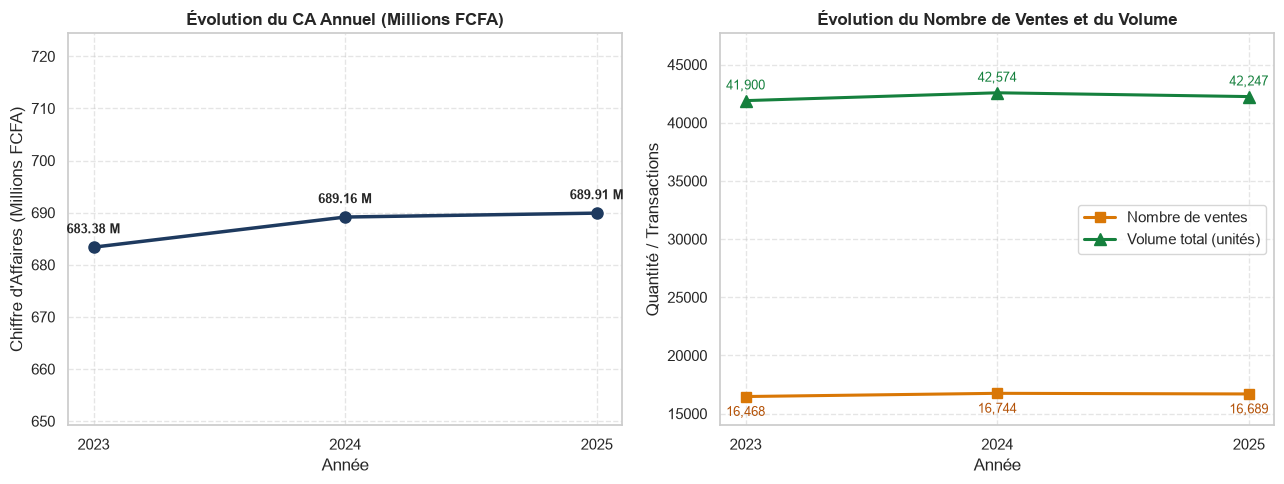

In [270]:

# 2. S'assurer que la colonne de date est au format datetime et extraire l'année
ventes["date_vente"] = pd.to_datetime(ventes["date_vente"])
ventes["annee"] = ventes["date_vente"].dt.year

# 3. Filtrer éventuellement les ventes validées si nécessaire
# Exemple : df_ventes = df_ventes[df_ventes["statut"].str.lower() == "validée"]

# 4. Calculer les agrégations par année
bilan_annuel = (
    ventes.groupby("annee", as_index=False)
    .agg(
        ca=("chiffre_affaire_net", "sum"),
        nombre_ventes=("id_vente", "nunique"),  # ou "count" selon votre structure
        volume_total=("quantite", "sum"),
    )
    .sort_values("annee")
)

# 5. Afficher le tableau récapitulatif et le total général
totaux = pd.DataFrame({
    "annee": ["Total"],
    "ca": [bilan_annuel["ca"].sum()],
    "nombre_ventes": [bilan_annuel["nombre_ventes"].sum()],
    "volume_total": [bilan_annuel["volume_total"].sum()],
})
print("--- Bilan annuel ---")
print(bilan_annuel.to_string(index=False))
print("\n--- Avec total général ---")
print(pd.concat([bilan_annuel, totaux], ignore_index=True).to_string(index=False))

# 6. Tracer les courbes de performance commerciale par année
annees_str = bilan_annuel["annee"].astype(int).astype(str)
ca_millions = bilan_annuel["ca"] / 1e6

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Courbe 1 : Chiffre d'Affaires annuel (en Millions FCFA)
ax1.plot(
    annees_str,
    ca_millions,
    marker="o",
    linewidth=2.5,
    markersize=8,
    color="#1E3A5F",
)
for x, y in zip(annees_str, ca_millions):
    ax1.annotate(
        f"{y:,.2f} M",
        (x, y),
        textcoords="offset points",
        xytext=(0, 10),
        ha="center",
        fontsize=9.5,
        fontweight="bold",
    )
ax1.set_title(
    "Évolution du CA Annuel (Millions FCFA)", fontsize=12, fontweight="bold"
)
ax1.set_xlabel("Année")
ax1.set_ylabel("Chiffre d'Affaires (Millions FCFA)")
ax1.set_ylim(ca_millions.min() * 0.95, ca_millions.max() * 1.05)
ax1.grid(True, linestyle="--", alpha=0.5)

# Courbe 2 : Nombre de ventes et Volume total par année
ax2.plot(
    annees_str,
    bilan_annuel["nombre_ventes"],
    marker="s",
    linewidth=2.2,
    markersize=7,
    color="#D97706",
    label="Nombre de ventes",
)
ax2.plot(
    annees_str,
    bilan_annuel["volume_total"],
    marker="^",
    linewidth=2.2,
    markersize=8,
    color="#15803D",
    label="Volume total (unités)",
)
for x, v, vol in zip(
    annees_str, bilan_annuel["nombre_ventes"], bilan_annuel["volume_total"]
):
    ax2.annotate(
        f"{v:,}",
        (x, v),
        textcoords="offset points",
        xytext=(0, -14),
        ha="center",
        fontsize=9,
        color="#B45309",
    )
    ax2.annotate(
        f"{vol:,}",
        (x, vol),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center",
        fontsize=9,
        color="#15803D",
    )
ax2.set_title(
    "Évolution du Nombre de Ventes et du Volume", fontsize=12, fontweight="bold"
)
ax2.set_xlabel("Année")
ax2.set_ylabel("Quantité / Transactions")
ax2.set_ylim(
    min(bilan_annuel["nombre_ventes"].min(), bilan_annuel["volume_total"].min())
    * 0.85,
    max(bilan_annuel["nombre_ventes"].max(), bilan_annuel["volume_total"].max())
    * 1.12,
)
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend()

plt.tight_layout()
plt.show()

•	Interprétation : L'activité reste très stable sur les trois ans (~683 à 690 M FCFA/an), avec un léger pic de ventes en 2024 et un CA maximal en 2025.

•	Conclusion métier : Le socle commercial est solide mais mature ; il faut activer de nouveaux leviers pour relancer la croissance.


Performance commercial par categorie de produit.

--- Performance par catégorie (ventes validées, hors Inconnue) ---
            categorie           ca  nombre_ventes  volume_total
              Boisson 618629403.35          15316         38682
             Épicerie 488408160.39          12670         32103
            Entretien 390334047.28           8865         22486
Produits Alimentaires 286521529.34           6666         17051
              Hygiène  38580863.52            828          2135
         Électronique  33954950.53            741          1926

--- Avec total général ---
            categorie            ca  nombre_ventes  volume_total
              Boisson  618629403.35          15316         38682
             Épicerie  488408160.39          12670         32103
            Entretien  390334047.28           8865         22486
Produits Alimentaires  286521529.34           6666         17051
              Hygiène   38580863.52            828          2135
         Électronique   33954950.53            741          1926
To

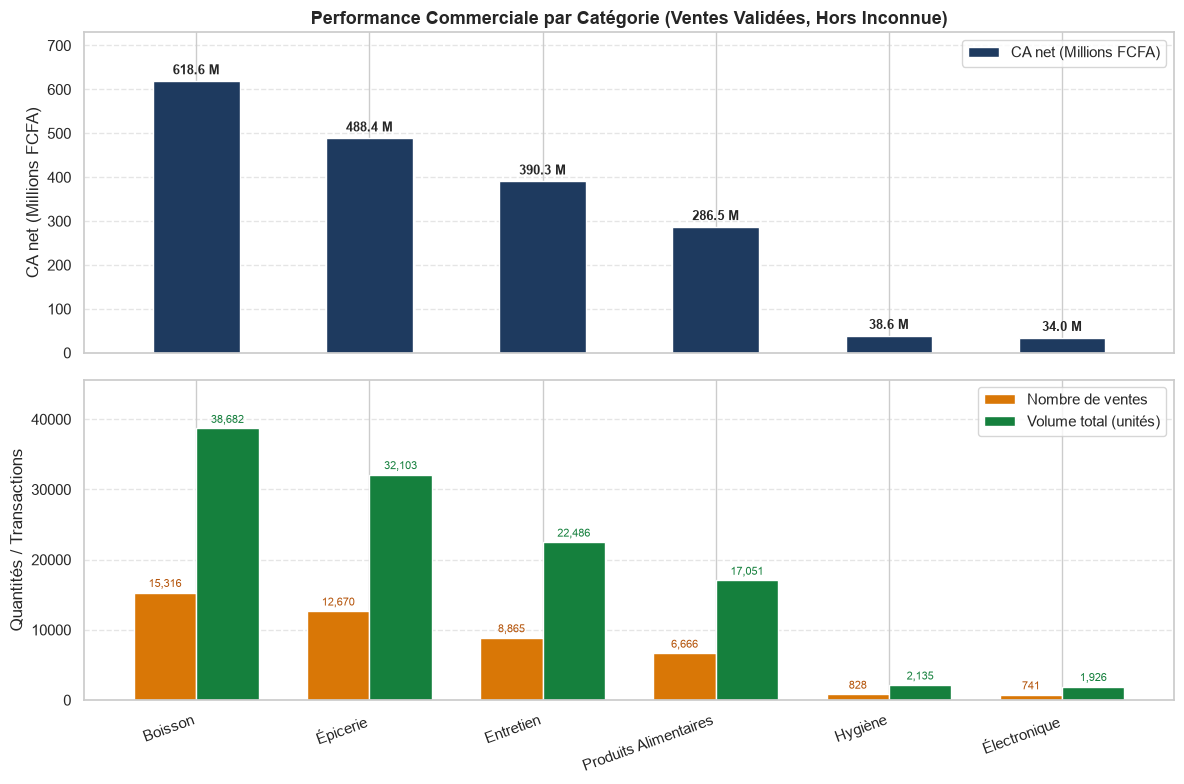

In [271]:
# 1. Filtrer les ventes validées et joindre la catégorie depuis la table produits
ventes_valides = ventes[ventes["statut_vente"].str.lower() == "validée"].copy()

ventes_cat = pd.merge(
    ventes_valides,
    produits[["id_produit", "categorie"]].drop_duplicates(subset=["id_produit"]),
    on="id_produit",
    how="left",
)

# Exclure la catégorie "Inconnue" et les valeurs manquantes
ventes_cat = ventes_cat[
    ventes_cat["categorie"].notna()
    & (ventes_cat["categorie"].astype(str).str.strip().str.lower() != "inconnue")
].copy()

# 2. Calculer CA (chiffre_affaire_net), nombre de ventes et volume total par catégorie
bilan_categorie = (
    ventes_cat.groupby("categorie", as_index=False)
    .agg(
        ca=("chiffre_affaire_net", "sum"),
        nombre_ventes=("id_vente", "nunique"),
        volume_total=("quantite", "sum"),
    )
    .sort_values("ca", ascending=False)
    .reset_index(drop=True)
)

totaux_cat = pd.DataFrame({
    "categorie": ["Total (hors Inconnue)"],
    "ca": [bilan_categorie["ca"].sum()],
    "nombre_ventes": [bilan_categorie["nombre_ventes"].sum()],
    "volume_total": [bilan_categorie["volume_total"].sum()],
})

print("--- Performance par catégorie (ventes validées, hors Inconnue) ---")
print(bilan_categorie.to_string(index=False))
print("\n--- Avec total général ---")
print(
    pd.concat([bilan_categorie, totaux_cat], ignore_index=True).to_string(
        index=False
    )
)

# 3. Graphique : CA net (Millions FCFA) + Nombre de ventes & Volume total
categories = bilan_categorie["categorie"]
ca_millions = bilan_categorie["ca"] / 1e6
x = np.arange(len(categories))
width = 0.36

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

bars_ca = ax1.bar(
    x, ca_millions, width=0.5, color="#1E3A5F", label="CA net (Millions FCFA)"
)
for bar in bars_ca:
    h = bar.get_height()
    ax1.annotate(
        f"{h:,.1f} M",
        (bar.get_x() + bar.get_width() / 2, h),
        textcoords="offset points",
        xytext=(0, 5),
        ha="center",
        fontsize=9,
        fontweight="bold",
    )
ax1.set_title(
    "Performance Commerciale par Catégorie (Ventes Validées, Hors Inconnue)",
    fontsize=13,
    fontweight="bold",
)
ax1.set_ylabel("CA net (Millions FCFA)")
ax1.set_ylim(0, ca_millions.max() * 1.18)
ax1.grid(axis="y", linestyle="--", alpha=0.5)
ax1.legend(loc="upper right")

bars_v = ax2.bar(
    x - width / 2,
    bilan_categorie["nombre_ventes"],
    width,
    color="#D97706",
    label="Nombre de ventes",
)
bars_vol = ax2.bar(
    x + width / 2,
    bilan_categorie["volume_total"],
    width,
    color="#15803D",
    label="Volume total (unités)",
)

for bar in bars_v:
    h = bar.get_height()
    ax2.annotate(
        f"{int(h):,}",
        (bar.get_x() + bar.get_width() / 2, h),
        textcoords="offset points",
        xytext=(0, 4),
        ha="center",
        fontsize=8,
        color="#B45309",
    )
for bar in bars_vol:
    h = bar.get_height()
    ax2.annotate(
        f"{int(h):,}",
        (bar.get_x() + bar.get_width() / 2, h),
        textcoords="offset points",
        xytext=(0, 4),
        ha="center",
        fontsize=8,
        color="#15803D",
    )

ax2.set_ylabel("Quantités / Transactions")
ax2.set_xticks(x)
ax2.set_xticklabels(categories, rotation=20, ha="right")
ax2.set_ylim(0, bilan_categorie["volume_total"].max() * 1.18)
ax2.grid(axis="y", linestyle="--", alpha=0.5)
ax2.legend(loc="upper right")

plt.tight_layout()
plt.show()

•	•	Interprétation : La performance est fortement concentrée sur Boisson (618,63 M FCFA ; 38 682 u) et Épicerie (488,41 M FCFA ; 32 103 u), suivies d'Entretien et Produits Alimentaires, tandis que Hygiène et Électronique restent marginales.

•	Conclusion métier : Concentrer les stocks et actions commerciales sur Boisson et Épicerie tout en maintenant la fiabilité du classement produit.



Impact des tranches de remise.

C:\Users\Agatte_Nganzeu\AppData\Local\Temp\ipykernel_22944\960056578.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=analyse_remises, x='tranche_remise', y='nb_ventes', ax=axes[0], palette='Oranges')
C:\Users\Agatte_Nganzeu\AppData\Local\Temp\ipykernel_22944\960056578.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=analyse_remises, x='tranche_remise', y='quantite_moyenne', ax=axes[1], palette='Purples')


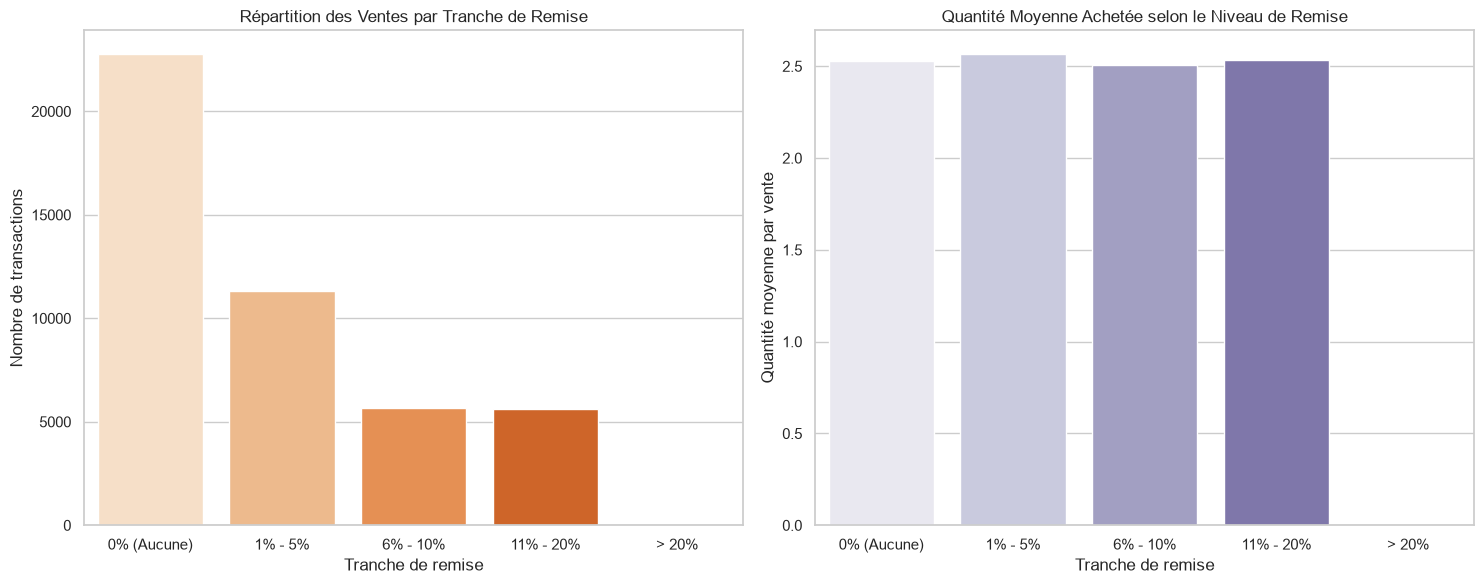

Part des ventes avec remise : 49.8%
Montant total des remises accordées : 77,439,829 FCFA


,tranche_remise,nb_ventes,quantite_moyenne,ca_net_total,perte_remise_totale
0,0% (Aucune),22769,2.53,977556034.00,0.00
1,1% - 5%,11297,2.57,473256189.31,17311125.69
2,6% - 10%,5652,2.51,214480600.82,23831184.18
3,11% - 20%,5637,2.54,205685980.77,36297519.23
4,> 20%,0,NaN,0.00,0.00


In [272]:


ventes_valides = ventes[ventes['statut_vente'].str.lower() == 'validée'].copy()

# Calculs de remises
ventes_valides['ca_brut'] = ventes_valides['quantite'] * ventes_valides['prix_unitaire_fcfa']
ventes_valides['montant_remise'] = ventes_valides['ca_brut'] - ventes_valides['chiffre_affaire_net']

# Tranches de remises
bins = [-0.001, 0, 0.05, 0.10, 0.20, 1.0]
labels = ['0% (Aucune)', '1% - 5%', '6% - 10%', '11% - 20%', '> 20%']
ventes_valides['tranche_remise'] = pd.cut(ventes_valides['remise_pct'], bins=bins, labels=labels)

analyse_remises = ventes_valides.groupby('tranche_remise', observed=False).agg(
    nb_ventes=('id_vente', 'count'),
    quantite_moyenne=('quantite', 'mean'),
    ca_net_total=('chiffre_affaire_net', 'sum'),
    perte_remise_totale=('montant_remise', 'sum')
).reset_index()

# Visualisation
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.barplot(data=analyse_remises, x='tranche_remise', y='nb_ventes', ax=axes[0], palette='Oranges')
axes[0].set_title("Répartition des Ventes par Tranche de Remise")
axes[0].set_xlabel("Tranche de remise")
axes[0].set_ylabel("Nombre de transactions")

sns.barplot(data=analyse_remises, x='tranche_remise', y='quantite_moyenne', ax=axes[1], palette='Purples')
axes[1].set_title("Quantité Moyenne Achetée selon le Niveau de Remise")
axes[1].set_xlabel("Tranche de remise")
axes[1].set_ylabel("Quantité moyenne par vente")

plt.tight_layout()
plt.show()

taux_ventes_remisees = (ventes_valides['remise_pct'] > 0).mean() * 100
print(f"Part des ventes avec remise : {taux_ventes_remisees:.1f}%")
print(f"Montant total des remises accordées : {ventes_valides['montant_remise'].sum():,.0f} FCFA")
display(analyse_remises)

•	Interprétation : Les ventes sans remise génèrent l'essentiel du CA net (977,56 M FCFA), alors que les remises de 11%–20% causent la plus forte perte (36,30 M FCFA) sans augmenter la quantité achetée par vente (~2,5 unités).

•	Conclusion métier : Plafonner ou conditionner les fortes remises (11%–20%) afin de préserver les marges.


### B. Analyse des clients.

Client les plus fideles.

C:\Users\Agatte_Nganzeu\AppData\Local\Temp\ipykernel_22944\2577533625.py:60: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


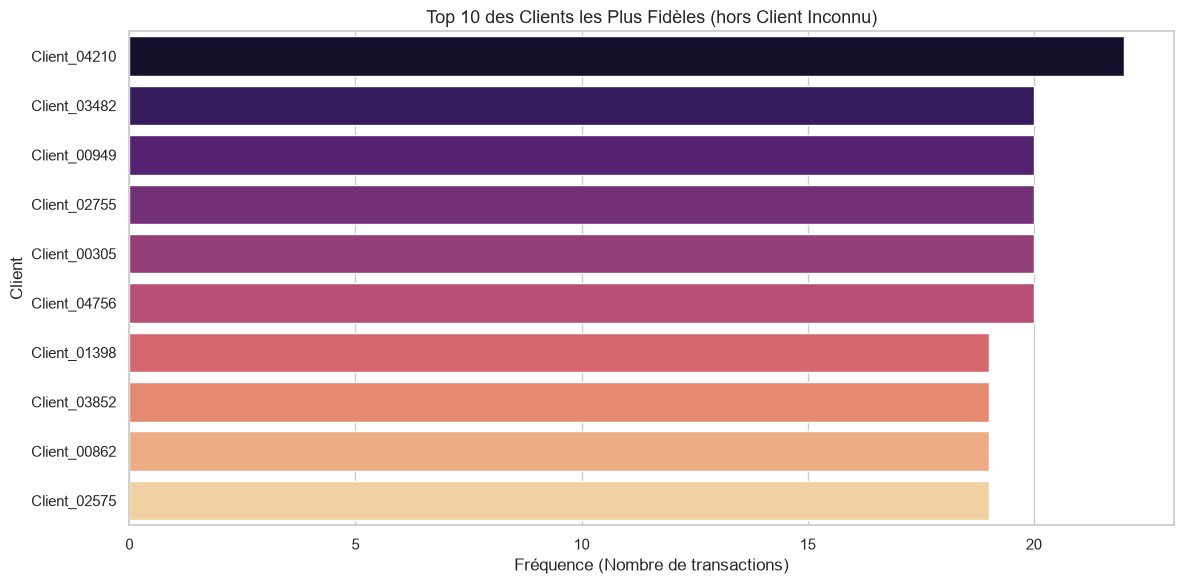

,id_client,nom_client,ville,ca_total,recence_jours,frequence,panier_moyen
0,CLI04210,Client_04210,Edéa,"932,138.00",28 j,22,"42,369.91"
1,CLI03482,Client_03482,Dschang,"1,019,460.01",49 j,20,"50,973.00"
2,CLI00949,Client_00949,Garoua,"989,806.50",34 j,20,"49,490.33"
3,CLI02755,Client_02755,Ebolowa,"827,091.00",30 j,20,"41,354.55"
4,CLI00305,Client_00305,Ebolowa,"715,672.50",86 j,20,"35,783.63"
5,CLI04756,Client_04756,Edéa,"634,670.50",26 j,20,"31,733.53"
6,CLI01398,Client_01398,Bafoussam,"1,524,921.99",33 j,19,"80,259.05"
7,CLI03852,Client_03852,Bertoua,"813,855.49",20 j,19,"42,834.50"
8,CLI00862,Client_00862,Bamenda,"690,995.50",55 j,19,"36,368.18"
9,CLI02575,Client_02575,Ngaoundéré,"660,030.50",6 j,19,"34,738.45"


In [273]:


# 1. Filtrer les ventes validées et exclure le client inconnu
ventes_valides = ventes[
    ventes["statut_vente"].str.lower() == "validée"
].copy()
ventes_valides = ventes_valides[
    ventes_valides["id_client"].notna()
    & (ventes_valides["id_client"].astype(str).str.upper() != "CL_INCONNU")
].copy()

# 2. Formater la date et définir la date de référence (+1 jour standard RFM)
ventes_valides["date_vente"] = pd.to_datetime(ventes_valides["date_vente"])
date_reference = ventes_valides["date_vente"].max() + pd.Timedelta(days=1)

# 3. Calculer Fréquence, CA total, Panier moyen et Récence par client
fidelite_client = ventes_valides.groupby("id_client", as_index=False).agg(
    frequence=("id_vente", "nunique"),
    ca_total=("chiffre_affaire_net", "sum"),
    panier_moyen=("chiffre_affaire_net", "mean"),
    derniere_vente=("date_vente", "max"),
)

fidelite_client["recence_jours"] = (
    date_reference - fidelite_client["derniere_vente"]
).dt.days

# 4. Joindre les informations clients et exclure à nouveau si besoin
fidelite_client = pd.merge(
    fidelite_client,
    clients[["id_client", "nom_client", "ville"]],
    on="id_client",
    how="left",
)
fidelite_client = fidelite_client[
    fidelite_client["id_client"].astype(str).str.upper() != "CL_INCONNU"
]

# 5. Top 10 des clients les plus fidèles
top_fidelite = (
    fidelite_client.sort_values(
        by=["frequence", "ca_total", "recence_jours"],
        ascending=[False, False, True],
    )
    .head(10)
    .reset_index(drop=True)
)

colonnes_affichage = [
    "id_client",
    "nom_client",
    "ville",
    "ca_total",
    "recence_jours",
    "frequence",
    "panier_moyen",
]
top_fidelite_affichage = top_fidelite[colonnes_affichage]

# 6. Visualisation
plt.figure(figsize=(12, 6))
sns.barplot(
    data=top_fidelite_affichage, x="frequence", y="nom_client", palette="magma"
)
plt.title(
    "Top 10 des Clients les Plus Fidèles (hors Client Inconnu)", fontsize=13
)
plt.xlabel("Fréquence (Nombre de transactions)")
plt.ylabel("Client")
plt.tight_layout()
plt.show()

# 7. Affichage du tableau
display(
    top_fidelite_affichage.style.format({
        "ca_total": "{:,.2f}",
        "panier_moyen": "{:,.2f}",
        "recence_jours": "{:.0f} j",
        "frequence": "{:.0f}",
    })
)

•	Interprétation : Clients très réguliers (19–22 achats) et actifs (6–86 j), avec un CA cumulé de ~0,63 à 1,52 M FCFA.

•	Conclusion métier : Maintenir l'engagement de ces clients réguliers par des offres de fidélité ciblées.


Clients ayant cesses d'acheter.

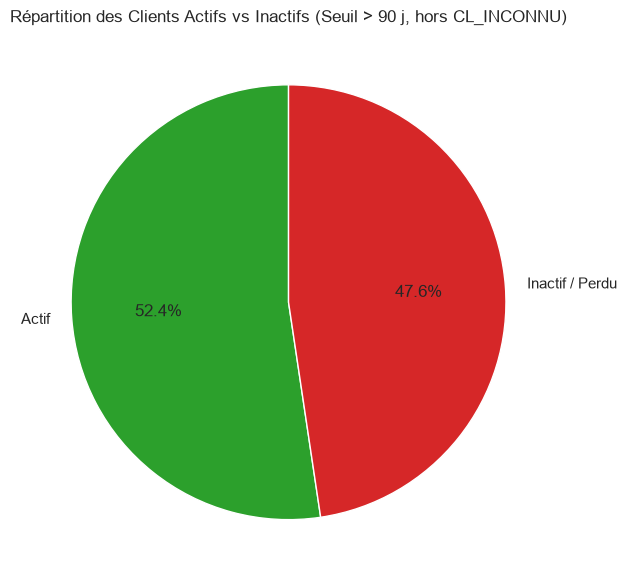

C:\Users\Agatte_Nganzeu\AppData\Local\Temp\ipykernel_22944\202975138.py:85: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


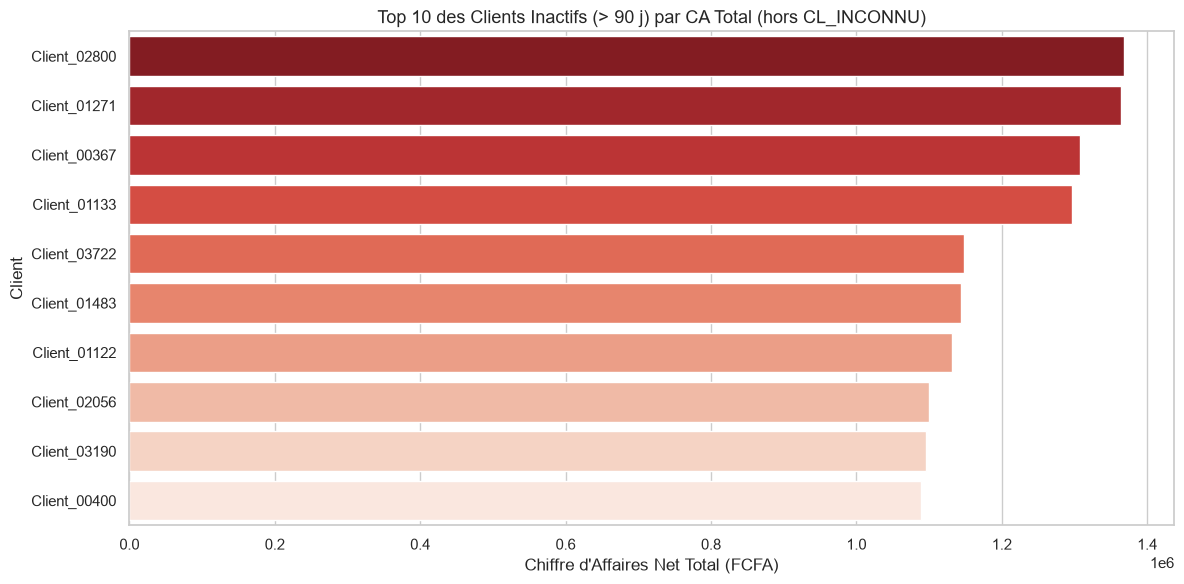

Date de référence : 2025-12-30
Clients inactifs (hors CL_INCONNU) : 2381
CA cumulé clients inactifs : 812,057,579.87 FCFA


,statut,nombre_clients
0,Actif,2617
1,Inactif / Perdu,2381


,id_client,nom_client,ville,ca_total,jours_depuis_dernier_achat,frequence,panier_moyen
0,CLI02800,Client_02800,Yaoundé,"1,368,480.01",461 j,7,"195,497.14"
1,CLI01271,Client_01271,Buea,"1,363,462.00",142 j,10,"136,346.20"
2,CLI00367,Client_00367,Ngaoundéré,"1,306,935.00",106 j,12,"108,911.25"
3,CLI01133,Client_01133,Bertoua,"1,296,588.00",249 j,10,"129,658.80"
4,CLI03722,Client_03722,Bafoussam,"1,148,217.00",159 j,6,"191,369.50"
5,CLI01483,Client_01483,Dschang,"1,144,238.50",128 j,14,"81,731.32"
6,CLI01122,Client_01122,Ngaoundéré,"1,131,818.00",116 j,12,"94,318.17"
7,CLI02056,Client_02056,Bafoussam,"1,100,060.49",101 j,12,"91,671.71"
8,CLI03190,Client_03190,Garoua,"1,095,557.49",108 j,17,"64,444.56"
9,CLI00400,Client_00400,Douala,"1,088,362.00",156 j,10,"108,836.20"


In [274]:


# 1. Filtrer les ventes validées et exclure le client inconnu
ventes_valides = ventes[
    ventes["statut_vente"].str.lower() == "validée"
].copy()
ventes_valides = ventes_valides[
    ventes_valides["id_client"].notna()
    & (ventes_valides["id_client"].astype(str).str.upper() != "CL_INCONNU")
].copy()

ventes_valides["date_vente"] = pd.to_datetime(ventes_valides["date_vente"])

# Date de référence = dernière date de vente du fichier
date_ref = ventes_valides["date_vente"].max()
seuil_inactivite = 90

# 2. Calculer CA, Fréquence, Panier moyen et Dernière visite par client
profil_clients = ventes_valides.groupby("id_client", as_index=False).agg(
    frequence=("id_vente", "nunique"),
    ca_total=("chiffre_affaire_net", "sum"),
    panier_moyen=("chiffre_affaire_net", "mean"),
    derniere_visite=("date_vente", "max"),
)

profil_clients["jours_depuis_dernier_achat"] = (
    date_ref - profil_clients["derniere_visite"]
).dt.days
profil_clients["statut_client"] = profil_clients[
    "jours_depuis_dernier_achat"
].apply(lambda x: "Inactif / Perdu" if x > seuil_inactivite else "Actif")

# Joindre les informations clients
profil_clients = pd.merge(
    profil_clients,
    clients[["id_client", "nom_client", "ville"]],
    on="id_client",
    how="left",
)
profil_clients = profil_clients[
    profil_clients["id_client"].astype(str).str.upper() != "CL_INCONNU"
]

# 3. Répartition Actifs vs Inactifs (hors CL_INCONNU)
repartition_statut = (
    profil_clients["statut_client"].value_counts().reset_index()
)
repartition_statut.columns = ["statut", "nombre_clients"]

plt.figure(figsize=(8, 6))
plt.pie(
    repartition_statut["nombre_clients"],
    labels=repartition_statut["statut"],
    autopct="%1.1f%%",
    colors=["#2ca02c", "#d62728"],
    startangle=90,
)
plt.title(
    f"Répartition des Clients Actifs vs Inactifs (Seuil > {seuil_inactivite} j, hors CL_INCONNU)"
)
plt.tight_layout()
plt.show()

# 4. Filtrer les clients inactifs et afficher le Top 10 par CA total
clients_inactifs = profil_clients[
    profil_clients["statut_client"] == "Inactif / Perdu"
].copy()
top_inactifs = (
    clients_inactifs.sort_values(
        by=["ca_total", "jours_depuis_dernier_achat"], ascending=[False, False]
    )
    .head(10)
    .reset_index(drop=True)
)

colonnes_affichage = [
    "id_client",
    "nom_client",
    "ville",
    "ca_total",
    "jours_depuis_dernier_achat",
    "frequence",
    "panier_moyen",
]

plt.figure(figsize=(12, 6))
sns.barplot(
    data=top_inactifs, x="ca_total", y="nom_client", palette="Reds_r"
)
plt.title(
    f"Top 10 des Clients Inactifs (> {seuil_inactivite} j) par CA Total (hors CL_INCONNU)",
    fontsize=13,
)
plt.xlabel("Chiffre d'Affaires Net Total (FCFA)")
plt.ylabel("Client")
plt.tight_layout()
plt.show()

print(f"Date de référence : {date_ref.strftime('%Y-%m-%d')}")
print(f"Clients inactifs (hors CL_INCONNU) : {len(clients_inactifs)}")
print(
    f"CA cumulé clients inactifs : {clients_inactifs['ca_total'].sum():,.2f} FCFA"
)
display(repartition_statut)
display(
    top_inactifs[colonnes_affichage].style.format({
        "ca_total": "{:,.2f}",
        "panier_moyen": "{:,.2f}",
        "jours_depuis_dernier_achat": "{:.0f} j",
        "frequence": "{:.0f}",
    })
)


•	Interprétation : Comptes à fort CA (~1,09–1,37 M FCFA) et paniers élevés, mais inactifs depuis 101 à 461 jours.

•	Conclusion métier : Prioriser une campagne de reconquête sur ces clients à forte valeur.


### C. Analyse des produits.

Produits les plus performants.

,nom_produit,categorie,CA,marge_brut,nombre_vente,quantite_total
0,Détergent Plus 122,Entretien,12898446.02,4574796.02,125,349
1,Riz Eco 394,Produits Alimentaires,10862196.02,3713292.02,106,294
2,Biscuit Eco 432,Produits Alimentaires,9783841.98,3558470.98,100,293
3,Biscuit Nature 378,Produits Alimentaires,10365659.50,3496434.50,105,275
4,Détergent Classique 124,Entretien,9923291.97,3310996.97,92,283
5,Jus Nature 217,Boisson,8863774.00,3302190.00,111,272
6,Huile Classique 96,Épicerie,7786827.72,2778655.72,98,247
7,Eau Nature 123,Boisson,7807080.01,2761908.01,103,222
8,Biscuit Premium 395,Produits Alimentaires,7407567.01,2726649.01,81,198
9,Eau Premium 77,Boisson,8082923.99,2694373.99,94,235


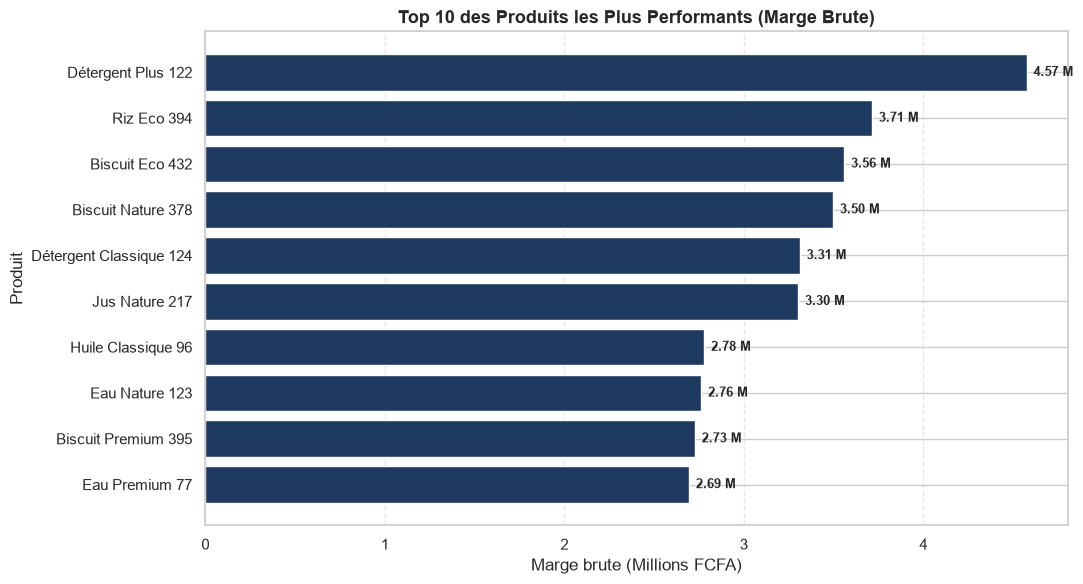

In [303]:
# 1. Filtrer les ventes validées et joindre nom_produit et categorie depuis produits
ventes_valides = ventes[
    ventes["statut_vente"].str.lower() == "validée"
].copy()

df_prod = pd.merge(
    ventes_valides,
    produits[["id_produit", "nom_produit", "categorie"]].drop_duplicates(
        subset=["id_produit"]
    ),
    on="id_produit",
    how="left",
)

# 2. Agréger par produit
perf_produits = df_prod.groupby(
    ["id_produit", "nom_produit", "categorie"], as_index=False
).agg(
    CA=("chiffre_affaire_net", "sum"),
    marge_brut=("marge_brute_ligne", "sum"),
    nombre_vente=("id_vente", "nunique"),
    quantite_total=("quantite", "sum"),
)

# 3. Top 10 des produits les plus performants selon marge_brut
top10_produits = (
    perf_produits.sort_values(by="marge_brut", ascending=False)
    .head(10)
    .reset_index(drop=True)
)

display(
    top10_produits[[
        "nom_produit",
        "categorie",
        "CA",
        "marge_brut",
        "nombre_vente",
        "quantite_total",
    ]]
)

# 4. Graphique Top 10 produits par marge_brut
plt.figure(figsize=(11, 6))
top10_plot = top10_produits.sort_values(by="marge_brut", ascending=True)
bars = plt.barh(
    top10_plot["nom_produit"], top10_plot["marge_brut"] / 1e6, color="#1E3A5F"
)
for bar in bars:
    w = bar.get_width()
    plt.annotate(
        f"{w:,.2f} M",
        (w, bar.get_y() + bar.get_height() / 2),
        textcoords="offset points",
        xytext=(5, 0),
        va="center",
        fontsize=9,
        fontweight="bold",
    )
plt.title(
    "Top 10 des Produits les Plus Performants (Marge Brute)",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel("Marge brute (Millions FCFA)")
plt.ylabel("Produit")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

•	Interprétation : Marges élevées (~2,69 à 4,57 M FCFA) soutenues par des volumes solides (198–349 unités), tirées notamment par Détergent Plus 122, Riz Eco 394, Biscuit Eco 432, Biscuit Nature 378 et Détergent Classique 124.

•	Conclusion métier : Garantir la disponibilité stock en priorité sur ces références phares (Détergent Plus 122, Riz Eco 394, gammes Biscuit et Détergent Classique 124) afin de sécuriser la marge globale.


Produits les moin performants.

,nom_produit,categorie,CA,marge_brut,nombre_vente,quantite_total
0,Eau Classique 485,Boisson,104640.00,22466.00,78,181
1,Café Eco 471,Boisson,171500.00,22634.00,91,258
2,Lait Famille 45,Boisson,211801.50,29433.50,81,164
3,Savon Famille 371,Entretien,250250.00,34503.00,96,259
4,Farine Eco 163,Épicerie,292050.00,38706.00,85,203
5,Savon Nature 247,Entretien,438283.50,44866.50,97,243
6,Huile Famille 138,Épicerie,247408.50,45556.50,103,267
7,Huile Famille 60,Épicerie,145830.00,47706.00,86,204
8,Sucre Plus 199,Épicerie,226734.00,48438.00,67,152
9,Huile Premium 386,Épicerie,625036.50,49162.50,93,214


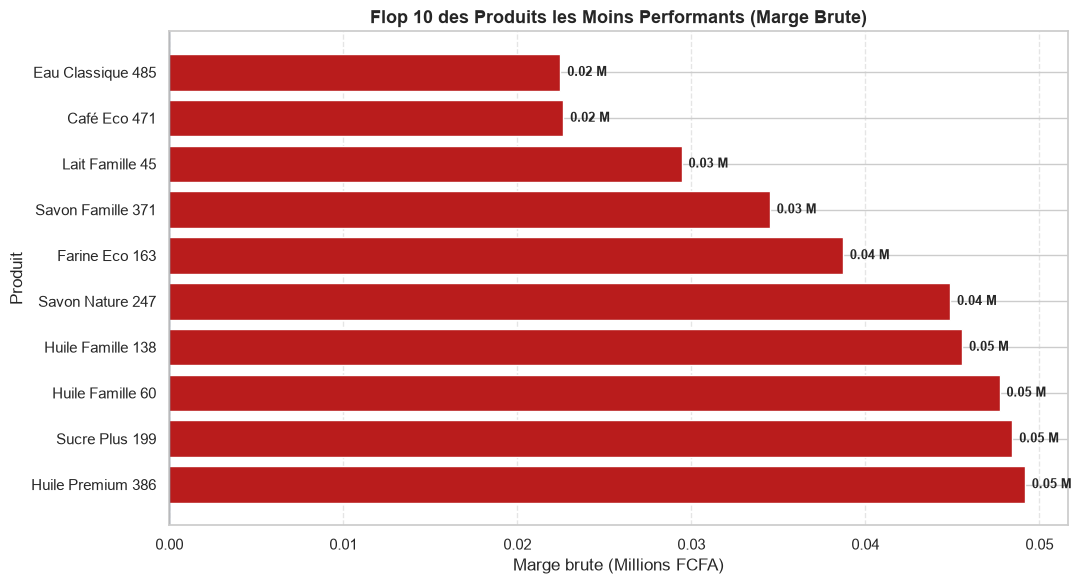

In [304]:
# 1. Flop 10 des produits les moins performants selon marge_brut
flop10_produits = (
    perf_produits.sort_values(by="marge_brut", ascending=True)
    .head(10)
    .reset_index(drop=True)
)

display(
    flop10_produits[[
        "nom_produit",
        "categorie",
        "CA",
        "marge_brut",
        "nombre_vente",
        "quantite_total",
    ]]
)

# 2. Graphique Flop 10 produits par marge_brut
plt.figure(figsize=(11, 6))
flop10_plot = flop10_produits.sort_values(by="marge_brut", ascending=False)
bars = plt.barh(
    flop10_plot["nom_produit"], flop10_plot["marge_brut"] / 1e6, color="#B91C1C"
)
for bar in bars:
    w = bar.get_width()
    offset_x = 5 if w >= 0 else -5
    ha_align = "left" if w >= 0 else "right"
    plt.annotate(
        f"{w:,.2f} M",
        (w, bar.get_y() + bar.get_height() / 2),
        textcoords="offset points",
        xytext=(offset_x, 0),
        ha=ha_align,
        va="center",
        fontsize=9,
        fontweight="bold",
    )
plt.axvline(0, color="#334155", linewidth=1)
plt.title(
    "Flop 10 des Produits les Moins Performants (Marge Brute)",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel("Marge brute (Millions FCFA)")
plt.ylabel("Produit")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

Interprétation : Ces produits génèrent très peu de marge (22,5 k à 49,2 k FCFA) malgré des volumes corrects (152 à 267 unités), car leur prix de vente est trop bas par rapport à leur coût d'achat.

Conclusion métier : Renégocier les prix d'achat avec les fournisseurs, limiter les remises accordées sur les produits très vendus (Huile Famille 138, Savon Famille 371, Café Eco 471) et augmenter les prix de vente sur les articles les moins rentables (Eau Classique 485, Lait Famille 45).

### D. Analyse geographique.

,ville,nom_magasin,CA,nombre_vente,quantite_total
0,Buea,Agence Buea,129421243.49,3032,7728
1,Yaoundé,Agence Yaoundé,128358751.13,3143,8053
2,Bertoua,Agence Bertoua,128308875.11,3060,7760
3,Garoua,Agence Garoua,127604561.12,3058,7799
4,Ngaoundéré,Agence Ngaoundéré,127300417.96,3059,7779
5,Kumba,Agence Kumba,126198591.08,2976,7728
6,Limbé,Agence Limbé,125864679.45,3079,7945
7,Bafoussam,Agence Bafoussam,124527288.07,2998,7591
8,Maroua,Agence Maroua,123789633.13,3050,7726
9,Bamenda,Agence Bamenda,123717378.04,2991,7650


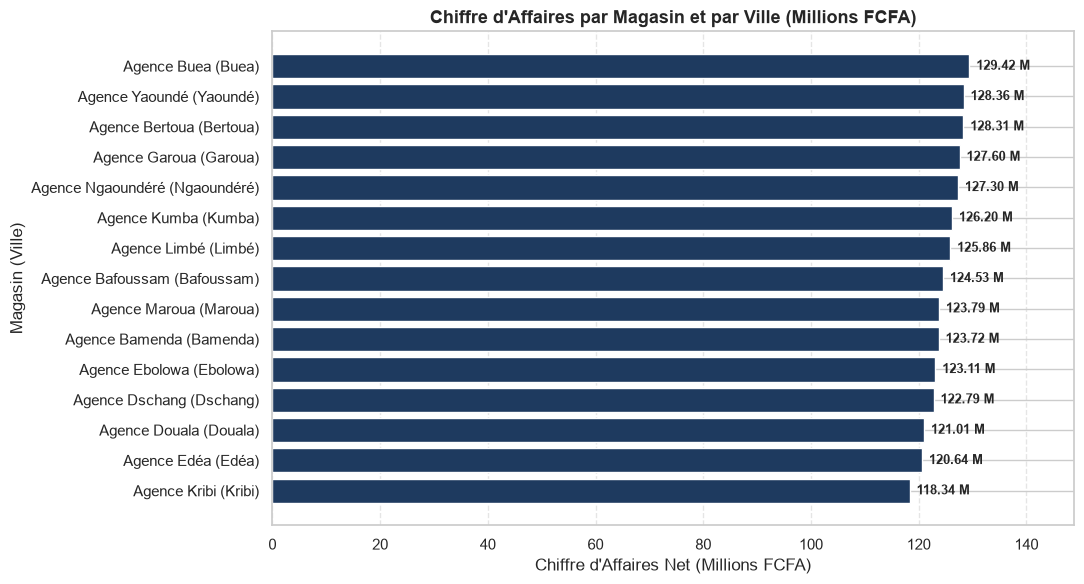

In [305]:
pd.set_option('display.float_format', lambda x: '%.2f' % x)

# 1. Fusionner ventes et magasins (si ce n'est pas déjà fait) et filtrer les ventes validées
df_geo = pd.merge(ventes, magasins, on='id_magasin', how='left')
ventes_valides_geo = df_geo[
    df_geo['statut_vente'].str.lower() == 'validée'
].copy()

# 2. Agrégation géographique par ville et par magasin
perf_geo = (
    ventes_valides_geo.groupby(['ville', 'nom_magasin'], as_index=False)
    .agg(
        CA=('chiffre_affaire_net', 'sum'),
        nombre_vente=('id_vente', 'nunique'),
        quantite_total=('quantite', 'sum'),
    )
    .sort_values(by='CA', ascending=False)
    .reset_index(drop=True)
)

# Affichage du tableau trié par CA décroissant
display(perf_geo)

# 3. Graphique en barres horizontales : CA par magasin et ville
plt.figure(figsize=(11, 6))
perf_geo_plot = perf_geo.sort_values(by='CA', ascending=True).copy()
perf_geo_plot['magasin_ville'] = (
    perf_geo_plot['nom_magasin'] + ' (' + perf_geo_plot['ville'] + ')'
)

bars = plt.barh(
    perf_geo_plot['magasin_ville'], perf_geo_plot['CA'] / 1e6, color='#1E3A5F'
)

for bar in bars:
    w = bar.get_width()
    plt.annotate(
        f'{w:,.2f} M',
        (w, bar.get_y() + bar.get_height() / 2),
        textcoords='offset points',
        xytext=(5, 0),
        va='center',
        fontsize=9,
        fontweight='bold',
    )

plt.title(
    "Chiffre d'Affaires par Magasin et par Ville (Millions FCFA)",
    fontsize=13,
    fontweight='bold',
)
plt.xlabel("Chiffre d'Affaires Net (Millions FCFA)")
plt.ylabel('Magasin (Ville)')
plt.xlim(0, (perf_geo_plot['CA'].max() / 1e6) * 1.15)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

•	Interprétation : Les 15 agences affichent des ventes très proches (118,34 à 129,42 M FCFA), avec Agence Buea en tête sur le chiffre d'affaires et Agence Yaoundé en tête sur les volumes (8 053 unités), tandis que Douala, Edéa et Kribi ferment la marche.

•	Conclusion métier : Maintenir l'approvisionnement des agences leaders (Buea, Yaoundé, Bertoua) et renforcer les actions commerciales dans les agences en retrait (Kribi, Edéa, Douala).



### E. Analyse des commerciaux.

Top 10 des commerciaux les plus performants.

,nom_commercial,CA,nombre_vente,quantite_totale,marge,objectif_mensuel_fcfa,taux_atteinte_pct
0,Commercial 40,41084220.55,956,2530,9966775.55,3500000.00,1173.83
1,Commercial 46,38557861.05,937,2519,9699408.05,3500000.00,1101.65
2,Commercial 15,41193960.00,931,2481,10259794.00,2000000.00,2059.70
3,Commercial 08,40577926.50,930,2475,10241205.50,7750000.00,523.59
4,Commercial 31,41133096.50,902,2458,10806887.50,2000000.00,2056.65
5,Commercial 01,40649381.49,973,2445,9853126.49,4000000.00,1016.23
6,Commercial 23,39082934.05,974,2442,9367609.05,5500000.00,710.60
7,Commercial 33,40015641.53,951,2432,10114752.53,2000000.00,2000.78
8,Commercial 42,39864300.53,948,2421,10143189.53,5750000.00,693.29
9,Commercial 24,38735132.99,941,2419,9551235.99,4250000.00,911.41


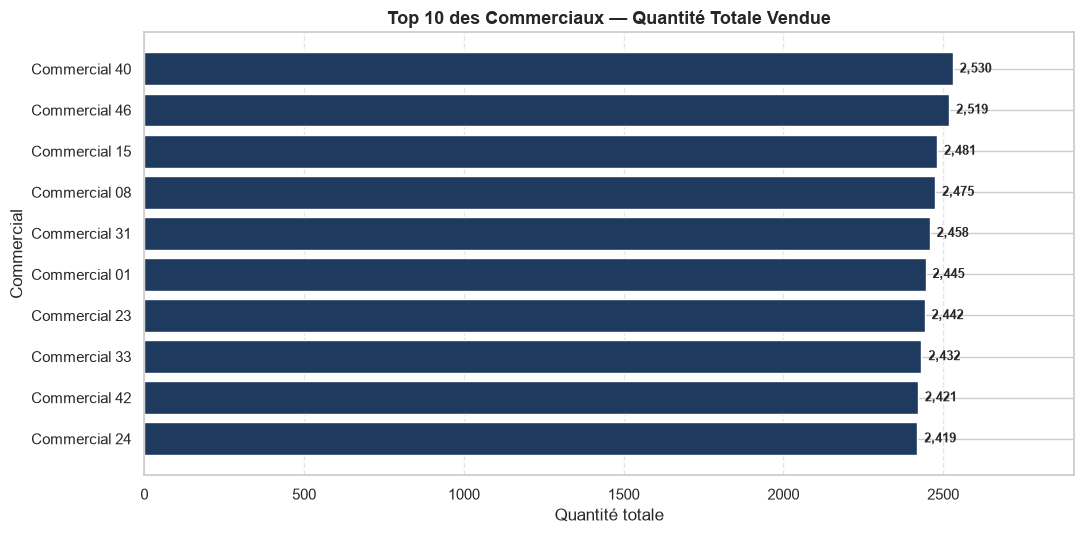

In [306]:
pd.set_option('display.float_format', lambda x: '%.2f' % x)

# 1. Fusionner ventes et commerciaux, puis filtrer les ventes validées
df_comm = pd.merge(ventes, commerciaux, on='id_commercial', how='left')
ventes_valides_comm = df_comm[
    df_comm['statut_vente'].str.lower() == 'validée'
].copy()

# 2. Agrégation par commercial et calcul du taux d'atteinte (%)
perf_commerciaux = (
    ventes_valides_comm.groupby(
        ['id_commercial', 'nom_commercial', 'objectif_mensuel_fcfa'],
        as_index=False,
    )
    .agg(
        CA=('chiffre_affaire_net', 'sum'),
        nombre_vente=('id_vente', 'count'),
        quantite_totale=('quantite', 'sum'),
        marge=('marge_brute_ligne', 'sum'),
    )
    .reset_index(drop=True)
)

perf_commerciaux['taux_atteinte_pct'] = (
    perf_commerciaux['CA'] / perf_commerciaux['objectif_mensuel_fcfa']
) * 100

cols_affichage = [
    'nom_commercial',
    'CA',
    'nombre_vente',
    'quantite_totale',
    'marge',
    'objectif_mensuel_fcfa',
    'taux_atteinte_pct',
]

# 3. Top 10 selon quantite_totale décroissante
top10_comm = (
    perf_commerciaux.sort_values(by='quantite_totale', ascending=False)
    .head(10)
    .reset_index(drop=True)
)

display(top10_comm[cols_affichage])

# 4. Graphique Top 10 commerciaux par quantite_totale
plt.figure(figsize=(11, 5.5))
top10_plot = top10_comm.sort_values(by='quantite_totale', ascending=True)
bars_top = plt.barh(
    top10_plot['nom_commercial'], top10_plot['quantite_totale'], color='#1E3A5F'
)

for bar in bars_top:
    w = bar.get_width()
    plt.annotate(
        f'{int(w):,}',
        (w, bar.get_y() + bar.get_height() / 2),
        textcoords='offset points',
        xytext=(5, 0),
        va='center',
        fontsize=9,
        fontweight='bold',
    )

plt.title(
    'Top 10 des Commerciaux — Quantité Totale Vendue',
    fontsize=13,
    fontweight='bold',
)
plt.xlabel('Quantité totale')
plt.ylabel('Commercial')
plt.xlim(0, top10_plot['quantite_totale'].max() * 1.15)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

•	Interprétation : Le Top 10 écoule entre 2 419 et 2 530 unités avec un chiffre d'affaires élevé (38,56 à 41,19 M FCFA) et un dépassement net des objectifs mensuels.

•	Conclusion métier : Réajuster les objectifs mensuels et capitaliser sur leurs pratiques.


Flop 10 des commerciaux les moins performants.

,nom_commercial,CA,nombre_vente,quantite_totale,marge,objectif_mensuel_fcfa,taux_atteinte_pct
0,Commercial 05,33585807.54,854,2098,8258002.54,6500000.00,516.70
1,Commercial 35,35075804.01,864,2100,8825779.01,7250000.00,483.80
2,Commercial 18,34858724.51,877,2108,8540013.51,6500000.00,536.29
3,Commercial 29,36441190.05,876,2127,9423809.05,7250000.00,502.64
4,Commercial 34,33608414.49,874,2140,8402166.49,6750000.00,497.90
5,Commercial 49,36120833.05,868,2140,9166575.05,3750000.00,963.22
6,Commercial 37,35999854.54,871,2161,8935599.54,7250000.00,496.55
7,Commercial 03,35035807.99,876,2184,8848124.99,3500000.00,1001.02
8,Commercial 50,36034968.06,859,2195,8769241.06,5250000.00,686.38
9,Commercial 43,35191652.04,890,2196,8691912.04,7250000.00,485.40


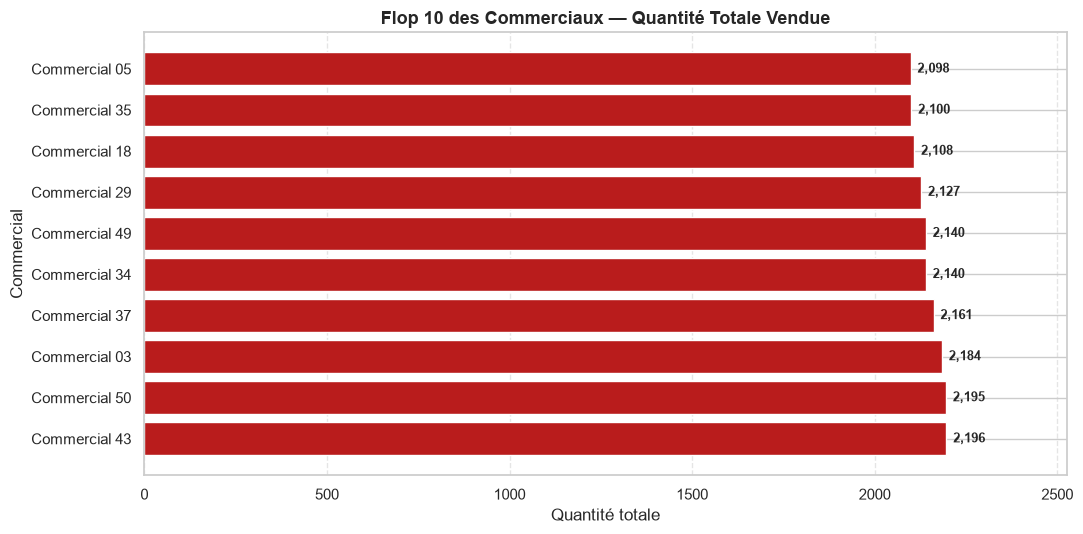

In [307]:
pd.set_option('display.float_format', lambda x: '%.2f' % x)

# 1. Fusionner ventes et commerciaux, puis filtrer les ventes validées
df_comm = pd.merge(ventes, commerciaux, on='id_commercial', how='left')
ventes_valides_comm = df_comm[
    df_comm['statut_vente'].str.lower() == 'validée'
].copy()

# 2. Agrégation par commercial et calcul du taux d'atteinte (%)
perf_commerciaux = (
    ventes_valides_comm.groupby(
        ['id_commercial', 'nom_commercial', 'objectif_mensuel_fcfa'],
        as_index=False,
    )
    .agg(
        CA=('chiffre_affaire_net', 'sum'),
        nombre_vente=('id_vente', 'count'),
        quantite_totale=('quantite', 'sum'),
        marge=('marge_brute_ligne', 'sum'),
    )
    .reset_index(drop=True)
)

perf_commerciaux['taux_atteinte_pct'] = (
    perf_commerciaux['CA'] / perf_commerciaux['objectif_mensuel_fcfa']
) * 100

cols_affichage = [
    'nom_commercial',
    'CA',
    'nombre_vente',
    'quantite_totale',
    'marge',
    'objectif_mensuel_fcfa',
    'taux_atteinte_pct',
]

# 3. Flop 10 selon quantite_totale croissante
flop10_comm = (
    perf_commerciaux.sort_values(by='quantite_totale', ascending=True)
    .head(10)
    .reset_index(drop=True)
)

display(flop10_comm[cols_affichage])

# 4. Graphique Flop 10 commerciaux par quantite_totale
plt.figure(figsize=(11, 5.5))
flop10_plot = flop10_comm.sort_values(by='quantite_totale', ascending=False)
bars_flop = plt.barh(
    flop10_plot['nom_commercial'],
    flop10_plot['quantite_totale'],
    color='#B91C1C',
)

for bar in bars_flop:
    w = bar.get_width()
    plt.annotate(
        f'{int(w):,}',
        (w, bar.get_y() + bar.get_height() / 2),
        textcoords='offset points',
        xytext=(5, 0),
        va='center',
        fontsize=9,
        fontweight='bold',
    )

plt.title(
    'Flop 10 des Commerciaux — Quantité Totale Vendue',
    fontsize=13,
    fontweight='bold',
)
plt.xlabel('Quantité totale')
plt.ylabel('Commercial')
plt.xlim(0, max(flop10_plot['quantite_totale'].max() * 1.15, 1))
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

•	Interprétation : Le Flop 10 vend entre 2 098 et 2 196 unités pour un chiffre d'affaires de 33,59 à 36,44 M FCFA, soit environ 300 à 430 unités de moins que le leader.

•	Conclusion métier : Accompagner ces commerciaux sur le volume par transaction et le suivi client afin de réduire l'écart avec le Top 10.


# Details

### 1.Analyse commercial.

 A. Evolution du chiffre d'affaire.

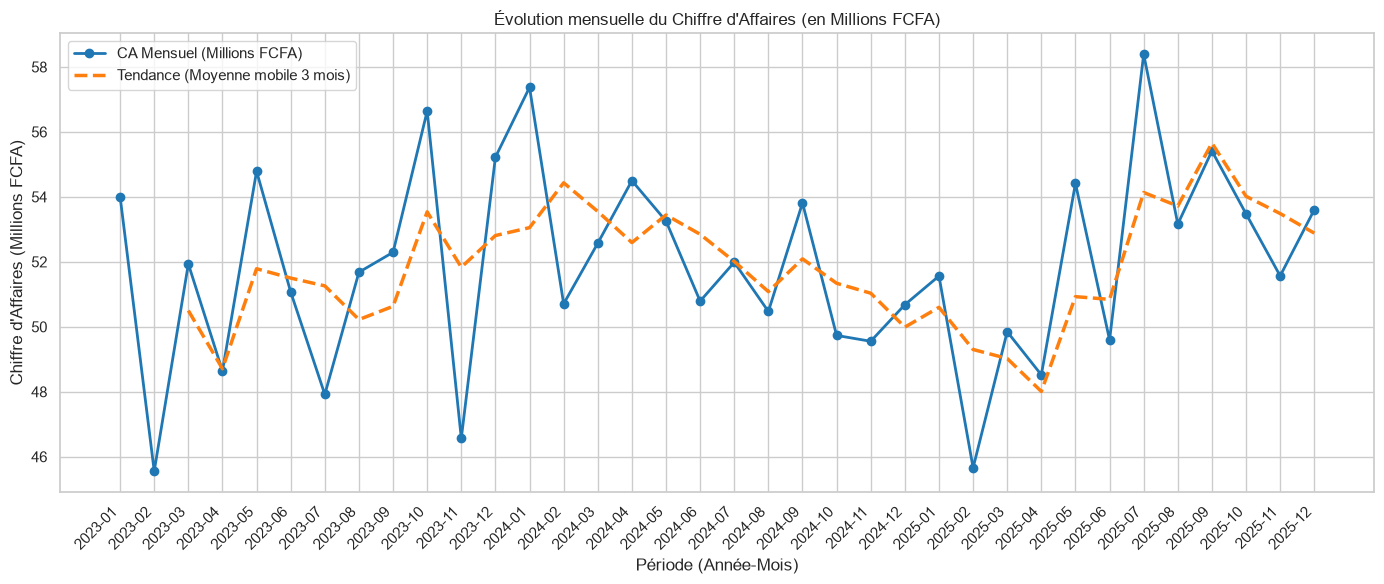

CA Total : 1,866,957,411 FCFA


In [277]:
# Configuration esthétique
sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams['figure.figsize'] = (12, 6)

# Filtrage sur les ventes validées et conversion des dates
ventes_valides = ventes[ventes['statut_vente'].str.lower() == 'validée'].copy()
ventes_valides['date_vente'] = pd.to_datetime(ventes_valides['date_vente'])
ventes_valides['annee_mois'] = ventes_valides['date_vente'].dt.to_period('M').astype(str)

# Agrégation du CA mensuel
ca_mensuel = ventes_valides.groupby('annee_mois')['chiffre_affaire_net'].sum().reset_index()
ca_mensuel['moyenne_mobile_3m'] = ca_mensuel['chiffre_affaire_net'].rolling(window=3).mean()

# Visualisation
fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(ca_mensuel['annee_mois'], ca_mensuel['chiffre_affaire_net'] / 1e6, 
        marker='o', linewidth=2, label='CA Mensuel (Millions FCFA)', color='#1f77b4')
ax.plot(ca_mensuel['annee_mois'], ca_mensuel['moyenne_mobile_3m'] / 1e6, 
        linestyle='--', linewidth=2.5, label='Tendance (Moyenne mobile 3 mois)', color='#ff7f0e')

ax.set_title("Évolution mensuelle du Chiffre d'Affaires (en Millions FCFA)")
ax.set_xlabel("Période (Année-Mois)")
ax.set_ylabel("Chiffre d'Affaires (Millions FCFA)")
plt.xticks(rotation=45, ha='right')
ax.legend()
plt.tight_layout()
plt.show()

print(f"CA Total : {ca_mensuel['chiffre_affaire_net'].sum():,.0f} FCFA")

Interprétation : Un chiffre d'affaires très instable d'un mois à l'autre, mais une tendance globale stable (autour de 50-54 millions de FCFA).

Conclusion métier : L'entreprise enregistre une activité globale stable mais subit de fortes variations mensuelles imprévisibles. Elle doit impérativement mieux anticiper ses stocks et ses livraisons pour éviter les ruptures de stock lors des pics de vente et maximiser son chiffre d'affaires.

B. Evolution des volumes de ventes.

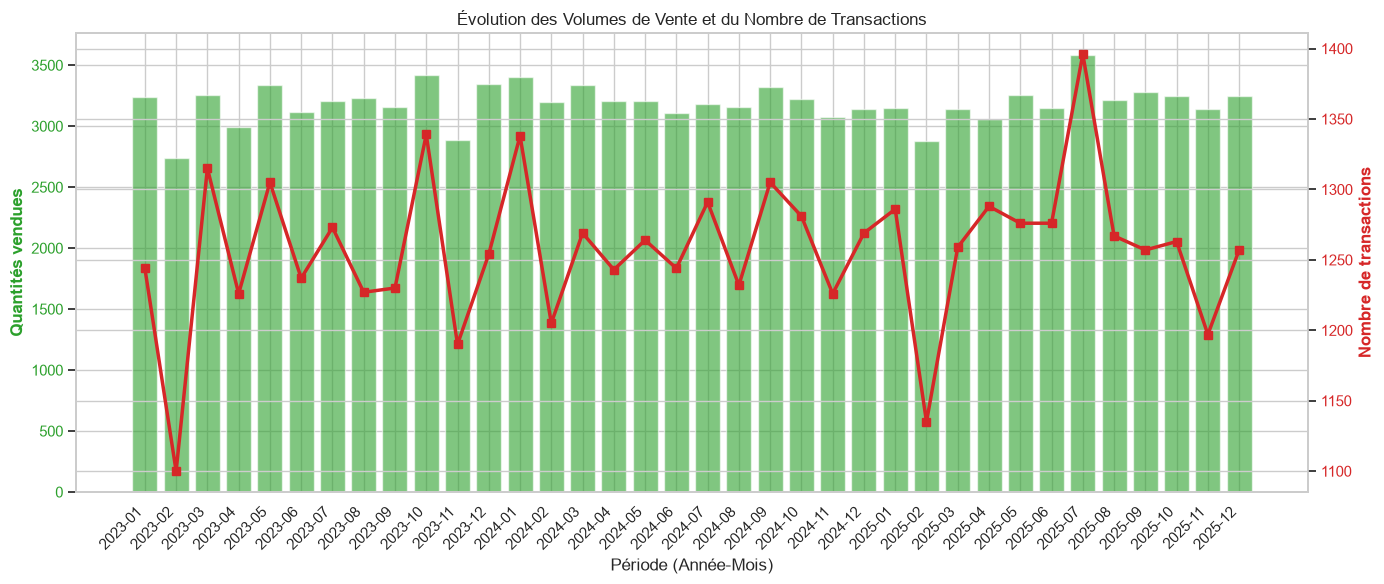

Volume total écoulé : 114,856 unités


In [278]:
# Filtrage sur les ventes validées et conversion des dates
ventes_valides = ventes[ventes['statut_vente'].str.lower() == 'validée'].copy()
ventes_valides['date_vente'] = pd.to_datetime(ventes_valides['date_vente'])
ventes_valides['annee_mois'] = ventes_valides['date_vente'].dt.to_period('M').astype(str)

# Agrégation des volumes et transactions
vol_mensuel = ventes_valides.groupby('annee_mois').agg(
    quantite_totale=('quantite', 'sum'),
    nb_transactions=('id_vente', 'nunique')
).reset_index()

# Graphique à double axe Y
fig, ax1 = plt.subplots(figsize=(14, 6))

color1 = '#2ca02c'
ax1.bar(vol_mensuel['annee_mois'], vol_mensuel['quantite_totale'], color=color1, alpha=0.6, label='Quantités vendues (Unités)')
ax1.set_xlabel("Période (Année-Mois)")
ax1.set_ylabel("Quantités vendues", color=color1, fontweight='bold')
ax1.tick_params(axis='y', labelcolor=color1)
plt.xticks(rotation=45, ha='right')

ax2 = ax1.twinx()
color2 = '#d62728'
ax2.plot(vol_mensuel['annee_mois'], vol_mensuel['nb_transactions'], color=color2, marker='s', linewidth=2.5, label='Nombre de transactions')
ax2.set_ylabel("Nombre de transactions", color=color2, fontweight='bold')
ax2.tick_params(axis='y', labelcolor=color2)

plt.title("Évolution des Volumes de Vente et du Nombre de Transactions")
fig.tight_layout()
plt.show()

print(f"Volume total écoulé : {vol_mensuel['quantite_totale'].sum():,} unités")

Interprétation : Les quantités vendues restent très stables d'un mois à l'autre, tandis que le nombre de transactions  fluctue beaucoup. Cela montre que la frequence des ventes change selon les périodes.

Conclusion métier : L'entreprise a une demande en volume bien régulière, mais doit adapter sa logistique aux variations du nombre de commandes pour éviter les ruptures lors des pics de transactions.

C. Analyse des ventes par categorie.

C:\Users\Agatte_Nganzeu\AppData\Local\Temp\ipykernel_22944\3566609954.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=perf_categorie, x='ca_total', y='categorie', ax=axes[0], palette='Blues_r')
C:\Users\Agatte_Nganzeu\AppData\Local\Temp\ipykernel_22944\3566609954.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=perf_categorie, x='volume_total', y='categorie', ax=axes[1], palette='Greens_r')
C:\Users\Agatte_Nganzeu\AppData\Local\Temp\ipykernel_22944\3566609954.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=perf_c

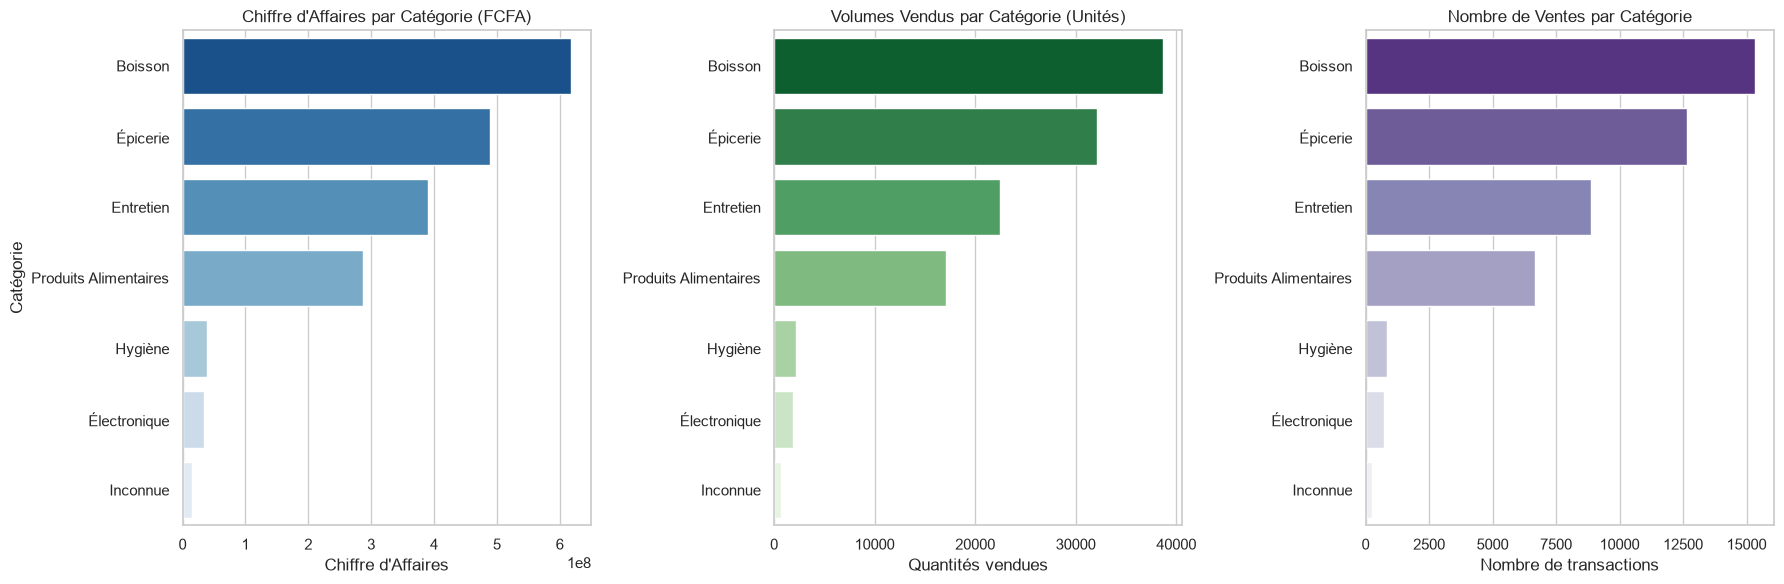

,categorie,ca_total,volume_total,nb_ventes
0,Boisson,618629403.35,38682,15316
1,Épicerie,488408160.39,32103,12670
2,Entretien,390334047.28,22486,8865
3,Produits Alimentaires,286521529.34,17051,6666
4,Hygiène,38580863.52,2135,828
5,Électronique,33954950.53,1926,741
6,Inconnue,14549850.49,707,269


In [279]:


ventes_valides = ventes[ventes['statut_vente'].str.lower() == 'validée'].copy()

# Jointure pour récupérer la catégorie
df_commercial = pd.merge(ventes_valides, produits[['id_produit', 'categorie']], on='id_produit', how='left')

perf_categorie = df_commercial.groupby('categorie').agg(
    ca_total=('chiffre_affaire_net', 'sum'),
    volume_total=('quantite', 'sum'),
    nb_ventes=('id_vente', 'count')
).sort_values(by='ca_total', ascending=False).reset_index()

# Visualisation comparative : CA vs Volume vs Nombre de ventes (3 graphiques)
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# 1. Chiffre d'Affaires
sns.barplot(data=perf_categorie, x='ca_total', y='categorie', ax=axes[0], palette='Blues_r')
axes[0].set_title("Chiffre d'Affaires par Catégorie (FCFA)")
axes[0].set_xlabel("Chiffre d'Affaires")
axes[0].set_ylabel("Catégorie")

# 2. Volumes Vendus
sns.barplot(data=perf_categorie, x='volume_total', y='categorie', ax=axes[1], palette='Greens_r')
axes[1].set_title("Volumes Vendus par Catégorie (Unités)")
axes[1].set_xlabel("Quantités vendues")
axes[1].set_ylabel("")

# 3. Nombre de Ventes (Transactions)
sns.barplot(data=perf_categorie, x='nb_ventes', y='categorie', ax=axes[2], palette='Purples_r')
axes[2].set_title("Nombre de Ventes par Catégorie")
axes[2].set_xlabel("Nombre de transactions")
axes[2].set_ylabel("")

plt.tight_layout()
plt.show()

display(perf_categorie)

Interprétation : Les six catégories principales contribuent de manière très équilibrée au chiffre d'affaires (autour de 290 à 315 millions de FCFA chacune). Cependant, Boisson et Hygiène génèrent le plus de transactions et de volumes vendus, tandis que Produits Alimentaires arrive en tête du chiffre d'affaires avec moins de commandes, indiquant un prix unitaire plus élevé. Une catégorie "Inconnue" représente environ 45 millions de FCFA. 

Conclusion métier : L'entreprise dispose d'une activité bien diversifiée sans dépendance à une seule famille de produits. Elle doit prioriser la disponibilité des stocks sur les produits à forte rotation (Boisson et Hygiène) pour soutenir le trafic client, tout en mettant en avant les Produits Alimentaires et l'Électronique pour maximiser le panier moyen.   

D. Analyse des ventes par saison.

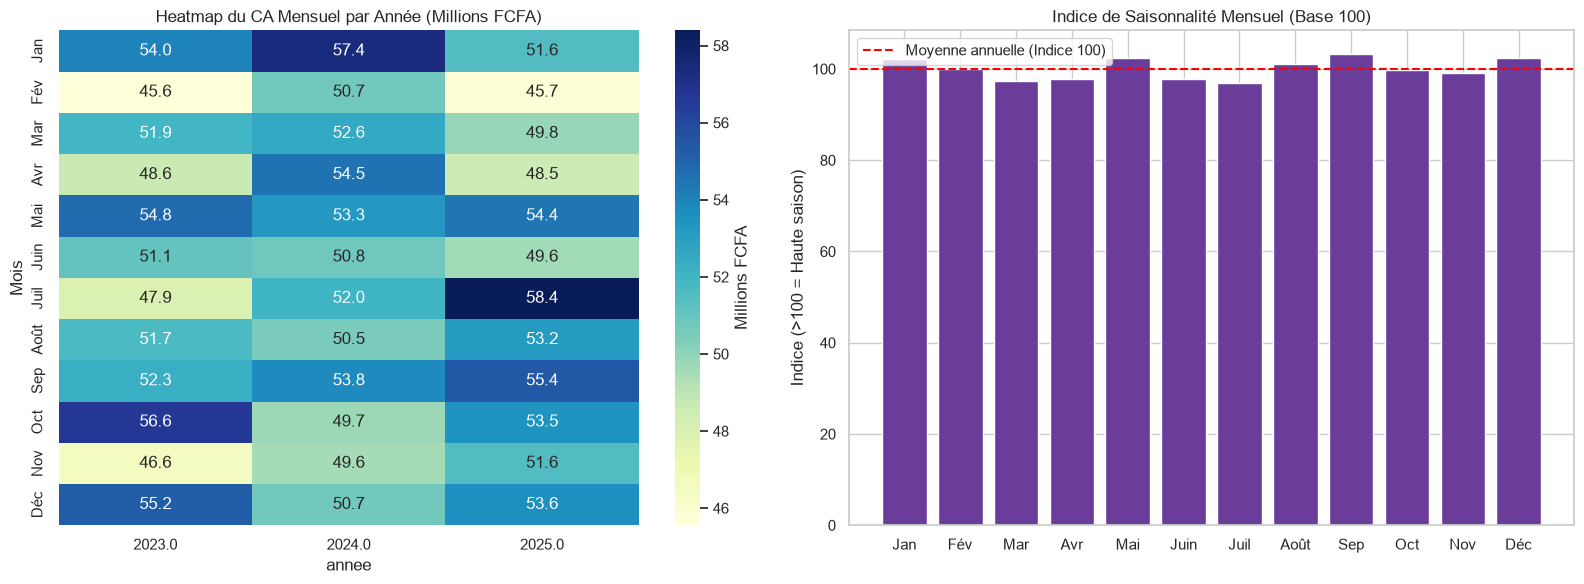

In [280]:

ventes_valides = ventes[ventes['statut_vente'].str.lower() == 'validée'].copy()
ventes_valides['date_vente'] = pd.to_datetime(ventes_valides['date_vente'])
ventes_valides['annee'] = ventes_valides['date_vente'].dt.year
ventes_valides['mois'] = ventes_valides['date_vente'].dt.month

# Table pivot Mois x Année
pivot_saison = ventes_valides.pivot_table(
    index='mois', 
    columns='annee', 
    values='chiffre_affaire_net', 
    aggfunc='sum'
)

noms_mois = ['Jan', 'Fév', 'Mar', 'Avr', 'Mai', 'Juin', 'Juil', 'Août', 'Sep', 'Oct', 'Nov', 'Déc']
pivot_saison.index = [noms_mois[int(m) - 1] for m in pivot_saison.index]

ca_moyen_par_mois = ventes_valides.groupby('mois')['chiffre_affaire_net'].mean()
indice_saison = (ca_moyen_par_mois / ca_moyen_par_mois.mean()) * 100

# Visualisation Heatmap et Indice
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(pivot_saison / 1e6, annot=True, fmt=".1f", cmap="YlGnBu", ax=axes[0], cbar_kws={'label': 'Millions FCFA'})
axes[0].set_title("Heatmap du CA Mensuel par Année (Millions FCFA)")
axes[0].set_ylabel("Mois")

axes[1].bar([noms_mois[int(m) - 1] for m in indice_saison.index], indice_saison.values, color='#6a3d9a')
axes[1].axhline(100, color='red', linestyle='--', linewidth=1.5, label='Moyenne annuelle (Indice 100)')
axes[1].set_title("Indice de Saisonnalité Mensuel (Base 100)")
axes[1].set_ylabel("Indice (>100 = Haute saison)")
axes[1].legend()

plt.tight_layout()
plt.show()

Interprétation : L'activité présente une saisonnalité relativement stable d'une année sur l'autre, avec des pics récurrents sur certains mois (comme en mai, septembre et décembre) et des creux constants (notamment en février et mars).

Conclusion métier : L'entreprise doit anticiper ses approvisionnements et renforcer ses équipes en amont des mois de forte saisonnalité pour éviter les ruptures, tout en lançant des campagnes promotionnelles ciblées pour stimuler les mois creux.

E. Comparaison des performances annuelles.

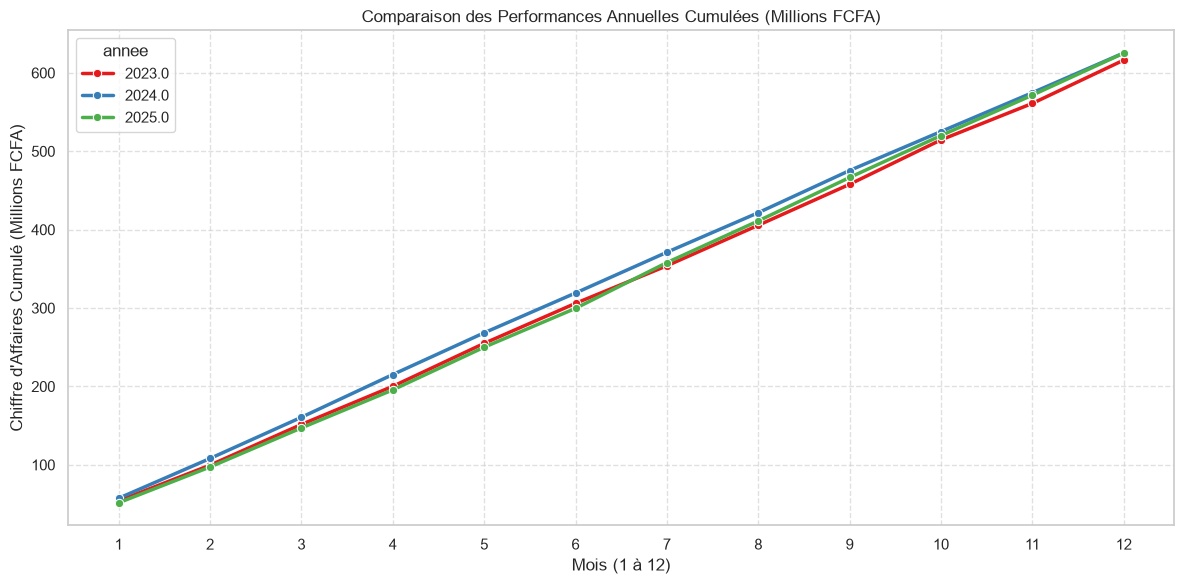

,annee,ca_annuel,volume_annuel,nb_transactions,panier_moyen,croissance_ca_pct
0,2023.00,616311379.61,37926,14940,41252.44,NaN
1,2024.00,625432118.31,38585,15167,41236.38,1.48
2,2025.00,625213913.46,38345,15157,41249.19,-0.03


In [281]:


ventes_valides = ventes[ventes['statut_vente'].str.lower() == 'validée'].copy()
ventes_valides['date_vente'] = pd.to_datetime(ventes_valides['date_vente'])
ventes_valides['annee'] = ventes_valides['date_vente'].dt.year
ventes_valides['mois'] = ventes_valides['date_vente'].dt.month

# Agrégation annuelle
perf_annuelle = ventes_valides.groupby('annee').agg(
    ca_annuel=('chiffre_affaire_net', 'sum'),
    volume_annuel=('quantite', 'sum'),
    nb_transactions=('id_vente', 'nunique'),
    panier_moyen=('chiffre_affaire_net', 'mean')
).reset_index()

perf_annuelle['croissance_ca_pct'] = perf_annuelle['ca_annuel'].pct_change() * 100

# Courbes cumulées annuelles (YTD)
ca_cumul = ventes_valides.groupby(['annee', 'mois'])['chiffre_affaire_net'].sum().groupby(level=0).cumsum().reset_index()

plt.figure(figsize=(12, 6))
sns.lineplot(data=ca_cumul, x='mois', y=ca_cumul['chiffre_affaire_net'] / 1e6, hue='annee', marker='o', palette='Set1', linewidth=2.5)
plt.title("Comparaison des Performances Annuelles Cumulées (Millions FCFA)")
plt.xlabel("Mois (1 à 12)")
plt.ylabel("Chiffre d'Affaires Cumulé (Millions FCFA)")
plt.xticks(range(1, 13))
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

display(perf_annuelle)

Interprétation : Les courbes de chiffre d'affaires cumulé progressent de manière presque identique d'une année sur l'autre (légère hausse en 2024 suivie d'une stabilisation en 2025 autour de 600-620 millions de FCFA annuels, avec un panier moyen stable à ~41 200 FCFA).

Conclusion métier : L'entreprise se trouve dans une phase de stagnation du chiffre d'affaires : l'activité ne recule pas, mais elle ne connaît plus de croissance significative. La direction doit impérativement trouver de nouveaux leviers commerciaux (conquête de nouveaux clients ou nouveaux produits) pour relancer la croissance.

F. Analyse des remises commerciales.

C:\Users\Agatte_Nganzeu\AppData\Local\Temp\ipykernel_22944\960056578.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=analyse_remises, x='tranche_remise', y='nb_ventes', ax=axes[0], palette='Oranges')
C:\Users\Agatte_Nganzeu\AppData\Local\Temp\ipykernel_22944\960056578.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=analyse_remises, x='tranche_remise', y='quantite_moyenne', ax=axes[1], palette='Purples')


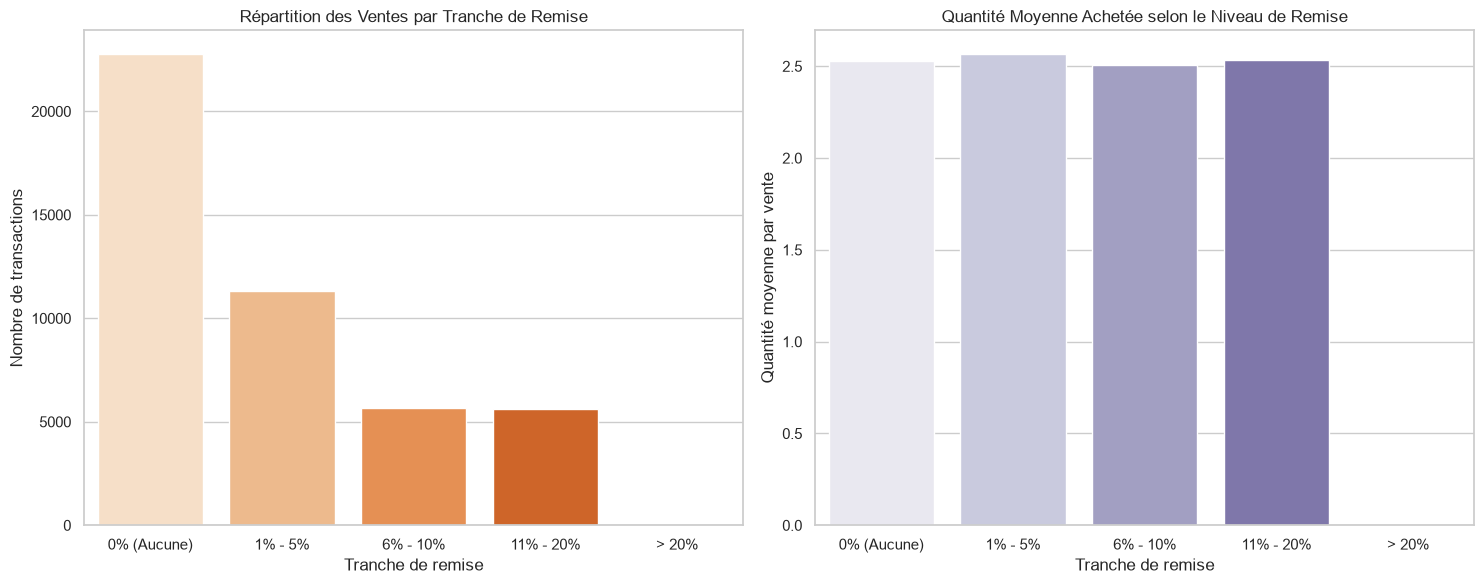

Part des ventes avec remise : 49.8%
Montant total des remises accordées : 77,439,829 FCFA


,tranche_remise,nb_ventes,quantite_moyenne,ca_net_total,perte_remise_totale
0,0% (Aucune),22769,2.53,977556034.00,0.00
1,1% - 5%,11297,2.57,473256189.31,17311125.69
2,6% - 10%,5652,2.51,214480600.82,23831184.18
3,11% - 20%,5637,2.54,205685980.77,36297519.23
4,> 20%,0,NaN,0.00,0.00


In [282]:


ventes_valides = ventes[ventes['statut_vente'].str.lower() == 'validée'].copy()

# Calculs de remises
ventes_valides['ca_brut'] = ventes_valides['quantite'] * ventes_valides['prix_unitaire_fcfa']
ventes_valides['montant_remise'] = ventes_valides['ca_brut'] - ventes_valides['chiffre_affaire_net']

# Tranches de remises
bins = [-0.001, 0, 0.05, 0.10, 0.20, 1.0]
labels = ['0% (Aucune)', '1% - 5%', '6% - 10%', '11% - 20%', '> 20%']
ventes_valides['tranche_remise'] = pd.cut(ventes_valides['remise_pct'], bins=bins, labels=labels)

analyse_remises = ventes_valides.groupby('tranche_remise', observed=False).agg(
    nb_ventes=('id_vente', 'count'),
    quantite_moyenne=('quantite', 'mean'),
    ca_net_total=('chiffre_affaire_net', 'sum'),
    perte_remise_totale=('montant_remise', 'sum')
).reset_index()

# Visualisation
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.barplot(data=analyse_remises, x='tranche_remise', y='nb_ventes', ax=axes[0], palette='Oranges')
axes[0].set_title("Répartition des Ventes par Tranche de Remise")
axes[0].set_xlabel("Tranche de remise")
axes[0].set_ylabel("Nombre de transactions")

sns.barplot(data=analyse_remises, x='tranche_remise', y='quantite_moyenne', ax=axes[1], palette='Purples')
axes[1].set_title("Quantité Moyenne Achetée selon le Niveau de Remise")
axes[1].set_xlabel("Tranche de remise")
axes[1].set_ylabel("Quantité moyenne par vente")

plt.tight_layout()
plt.show()

taux_ventes_remisees = (ventes_valides['remise_pct'] > 0).mean() * 100
print(f"Part des ventes avec remise : {taux_ventes_remisees:.1f}%")
print(f"Montant total des remises accordées : {ventes_valides['montant_remise'].sum():,.0f} FCFA")
display(analyse_remises)

Interprétation : Près de la moitié des ventes (49.8%) bénéficient d'une remise, représentant un manque à gagner de plus de 77 millions de FCFA. Cependant, la quantité moyenne achetée reste identique (environ 2,5 articles) peu importe le niveau de réduction accordé.

Conclusion métier : Les remises actuelles rognent inutilement la marge de l'entreprise sans stimuler les volumes d'achat. Il est urgent de restreindre ou de conditionner l'octroi des remises à de gros volumes d'achat pour protéger la rentabilité.

### 2. Analyse des clients.

A. Frequence d'achat.

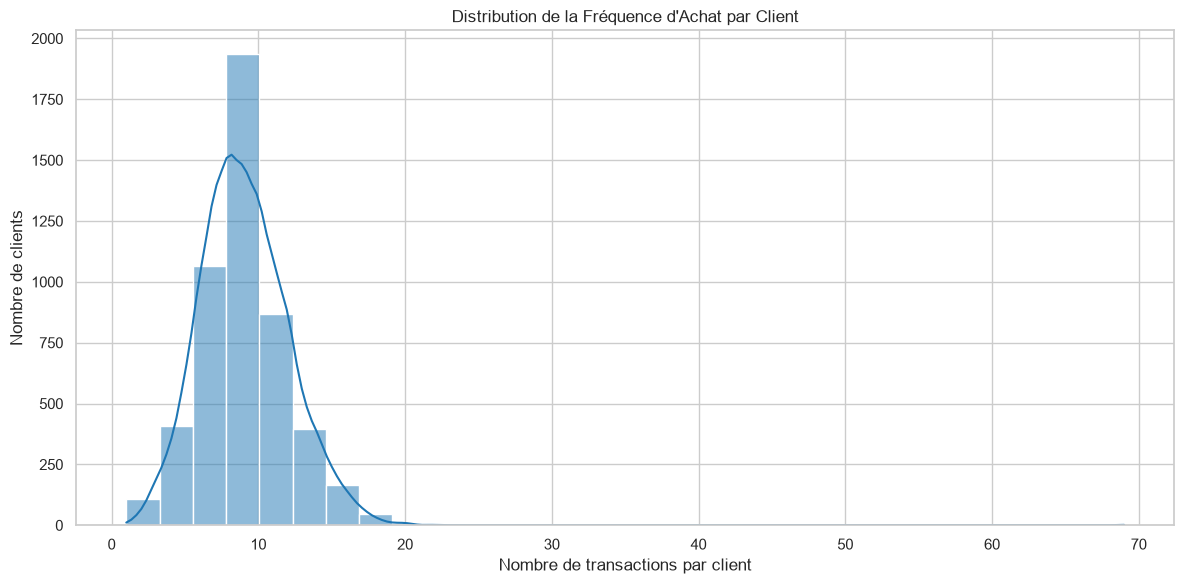

Nombre moyen d'achats par client : 9.07


,nb_achats
count,4999.00
mean,9.07
std,3.08
min,1.00
25%,7.00
50%,9.00
75%,11.00
max,69.00


In [283]:


ventes_valides = ventes[ventes['statut_vente'].str.lower() == 'validée'].copy()

# Fréquence : nombre de transactions uniques par client
frequence_client = ventes_valides.groupby('id_client')['id_vente'].nunique().reset_index()
frequence_client.columns = ['id_client', 'nb_achats']

# Visualisation
plt.figure(figsize=(12, 6))
sns.histplot(frequence_client['nb_achats'], bins=30, kde=True, color='#1f77b4')
plt.title("Distribution de la Fréquence d'Achat par Client")
plt.xlabel("Nombre de transactions par client")
plt.ylabel("Nombre de clients")
plt.tight_layout()
plt.show()

print(f"Nombre moyen d'achats par client : {frequence_client['nb_achats'].mean():.2f}")
display(frequence_client.describe())

Interprétation : En moyenne, un client achète environ 9 fois. La grande majorité des clients a un comportement d'achat très régulier, avec quelques acheteurs exceptionnels.

Conclusion métier : L'entreprise a une clientèle stable et fidèle. Elle doit mettre en place des avantages pour récompenser ses meilleurs clients et encourager les autres à acheter un peu plus souvent.

B. Montant moyen depense.

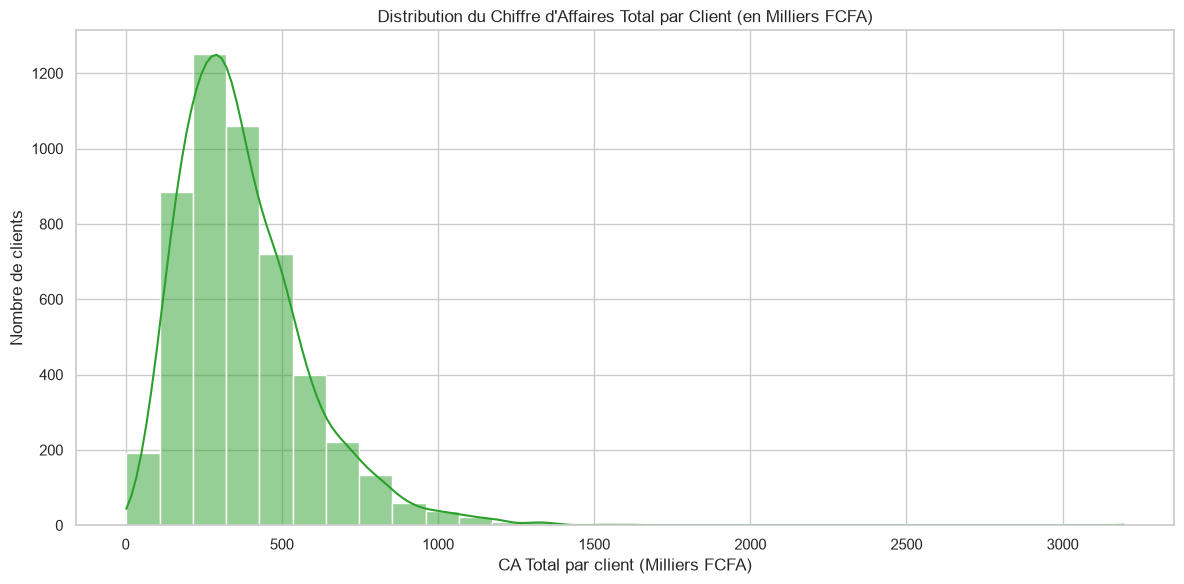

CA moyen par client : 374,271 FCFA


,id_client,ca_total,panier_moyen,nb_achats
4998,CL_INCONNU,3196788.51,46330.27,69
587,CLI00588,1611609.52,123969.96,13
1397,CLI01398,1524921.99,80259.05,19
2798,CLI02800,1368480.01,195497.14,7
1270,CLI01271,1363462.00,136346.20,10
2278,CLI02280,1359675.01,97119.64,14
1713,CLI01715,1326357.98,88423.87,15
845,CLI00846,1321323.50,94380.25,14
4175,CLI04178,1311076.01,72837.56,18
366,CLI00367,1306935.00,108911.25,12


In [284]:

ventes_valides = ventes[ventes['statut_vente'].str.lower() == 'validée'].copy()

# CA total et montant moyen par client
montant_client = ventes_valides.groupby('id_client').agg(
    ca_total=('chiffre_affaire_net', 'sum'),
    panier_moyen=('chiffre_affaire_net', 'mean'),
    nb_achats=('id_vente', 'nunique')
).reset_index()

# Visualisation
plt.figure(figsize=(12, 6))
sns.histplot(montant_client['ca_total'] / 1e3, bins=30, kde=True, color='#2ca02c')
plt.title("Distribution du Chiffre d'Affaires Total par Client (en Milliers FCFA)")
plt.xlabel("CA Total par client (Milliers FCFA)")
plt.ylabel("Nombre de clients")
plt.tight_layout()
plt.show()

print(f"CA moyen par client : {montant_client['ca_total'].mean():,.0f} FCFA")
display(montant_client.sort_values(by='ca_total', ascending=False).head(10))

Interprétation : La plupart des clients dépensent entre 200 000 et 500 000 FCFA, sauf quelques rares clients VIP qui montent jusqu'à 3 millions.

Conclusion métier : Il faut accorder une attention privilégiée à ces gros acheteurs et trouver des astuces pour encourager les clients classiques à dépenser un peu plus.

C. Clients les plus fideles.

C:\Users\Agatte_Nganzeu\AppData\Local\Temp\ipykernel_22944\18994360.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_fidelite, x='nb_achats', y='nom_client', palette='magma')


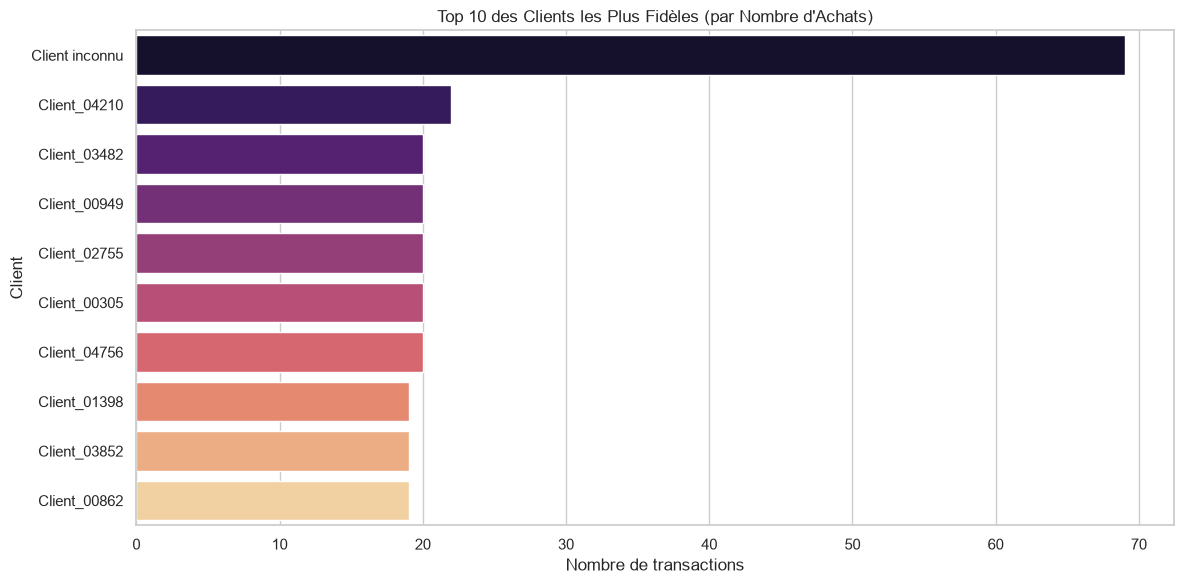

,id_client,nb_achats,ca_total,panier_moyen,nom_client,ville
4998,CL_INCONNU,69,3196788.51,46330.27,Client inconnu,Inconnue
4207,CLI04210,22,932138.00,42369.91,Client_04210,Edéa
3480,CLI03482,20,1019460.01,50973.00,Client_03482,Dschang
948,CLI00949,20,989806.50,49490.33,Client_00949,Garoua
2753,CLI02755,20,827091.00,41354.55,Client_02755,Ebolowa
304,CLI00305,20,715672.50,35783.63,Client_00305,Ebolowa
4753,CLI04756,20,634670.50,31733.53,Client_04756,Edéa
1397,CLI01398,19,1524921.99,80259.05,Client_01398,Bafoussam
3850,CLI03852,19,813855.49,42834.50,Client_03852,Bertoua
861,CLI00862,19,690995.50,36368.18,Client_00862,Bamenda


In [285]:


ventes_valides = ventes[ventes['statut_vente'].str.lower() == 'validée'].copy()

fidelite_client = ventes_valides.groupby('id_client').agg(
    nb_achats=('id_vente', 'nunique'),
    ca_total=('chiffre_affaire_net', 'sum'),
    panier_moyen=('chiffre_affaire_net', 'mean')
).reset_index()

fidelite_client = pd.merge(fidelite_client, clients[['id_client', 'nom_client', 'ville']], on='id_client', how='left')
top_fidelite = fidelite_client.sort_values(by=['nb_achats', 'ca_total'], ascending=False).head(10)

# Visualisation Top 10 fidèles
plt.figure(figsize=(12, 6))
sns.barplot(data=top_fidelite, x='nb_achats', y='nom_client', palette='magma')
plt.title("Top 10 des Clients les Plus Fidèles (par Nombre d'Achats)")
plt.xlabel("Nombre de transactions")
plt.ylabel("Client")
plt.tight_layout()
plt.show()

display(top_fidelite)

Interprétation : Un "Client inconnu" arrive largement en tête avec 69 achats, suivi des meilleurs clients qui oscillent entre 19 et 22 transactions.   

Conclusion métier : Il faut identifier ce "Client inconnu" et proposer des avantages aux clients les plus réguliers.

D. Clients ayant cesse d'acheter.

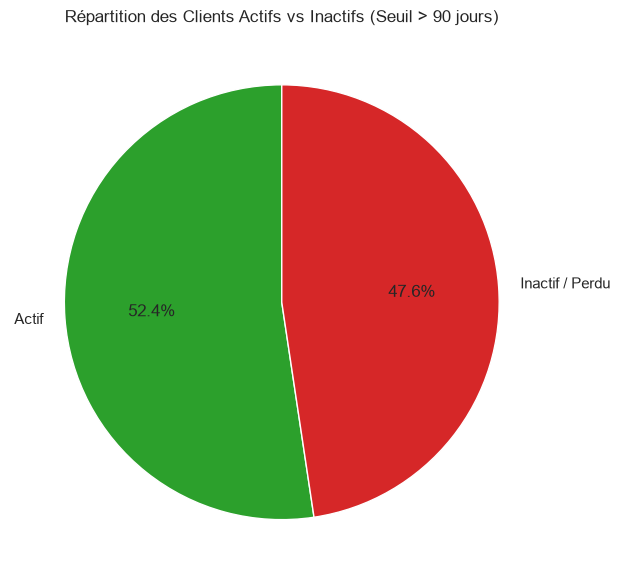

Date de référence de l'analyse : 2025-12-30


,statut,nombre_clients
0,Actif,2618
1,Inactif / Perdu,2381


In [286]:

ventes_valides = ventes[ventes['statut_vente'].str.lower() == 'validée'].copy()
ventes_valides['date_vente'] = pd.to_datetime(ventes_valides['date_vente'])

# Date de référence = dernière date de vente du fichier
date_ref = ventes_valides['date_vente'].max()

# Dernière date d'achat par client
derniere_visite = ventes_valides.groupby('id_client')['date_vente'].max().reset_index()
derniere_visite['jours_depuis_dernier_achat'] = (date_ref - derniere_visite['date_vente']).dt.days

# Seuil d'inactivité (ex: pas d'achat depuis plus de 90 jours)
seuil_inactivite = 90
derniere_visite['statut_client'] = derniere_visite['jours_depuis_dernier_achat'].apply(
    lambda x: 'Inactif / Perdu' if x > seuil_inactivite else 'Actif'
)

repartition_statut = derniere_visite['statut_client'].value_counts().reset_index()
repartition_statut.columns = ['statut', 'nombre_clients']

# Visualisation Camembert
plt.figure(figsize=(8, 6))
plt.pie(repartition_statut['nombre_clients'], labels=repartition_statut['statut'], autopct='%1.1f%%', colors=['#2ca02c', '#d62728'], startangle=90)
plt.title(f"Répartition des Clients Actifs vs Inactifs (Seuil > {seuil_inactivite} jours)")
plt.tight_layout()
plt.show()

print(f"Date de référence de l'analyse : {date_ref.strftime('%Y-%m-%d')}")
display(repartition_statut)

Interprétation : Près de la moitié des clients (47,6%) n'ont pas acheté depuis plus de 90 jours et sont considérés comme inactifs.   

Conclusion métier : L'entreprise souffre d'une perte importante de clients. Elle doit rapidement lancer des campagnes de relance ciblées pour réengager ces acheteurs inactifs avant de les perdre définitivement.   


E. Segmentation RFM (Recence, Frequence, Montant).

In [287]:



ventes_valides = ventes[ventes['statut_vente'].str.lower() == 'validée'].copy()
ventes_valides['date_vente'] = pd.to_datetime(ventes_valides['date_vente'])
date_ref = ventes_valides['date_vente'].max() + pd.Timedelta(days=1)

# Groupement par client pour obtenir uniquement les 3 paramètres
rfm_brut = ventes_valides.groupby('id_client').agg(
    recence_jours=('date_vente', lambda x: (date_ref - x.max()).days),
    frequence_achats=('id_vente', 'nunique'),
    montant_total=('chiffre_affaire_net', 'sum')
).reset_index()

display(rfm_brut.head(10))
print(f"Nombre total de clients analysés : {len(rfm_brut)}")

,id_client,recence_jours,frequence_achats,montant_total
0,CLI00001,46,8,364813.00
1,CLI00002,17,10,631020.00
2,CLI00003,17,14,583070.50
3,CLI00004,48,14,708349.00
4,CLI00005,13,12,638958.01
5,CLI00006,10,8,215054.00
6,CLI00007,165,10,262532.50
7,CLI00008,526,7,294287.00
8,CLI00009,12,10,277276.00
9,CLI00010,190,5,99480.00


Nombre total de clients analysés : 4999


Interprétation : Le tableau montre la récence (jours depuis le dernier achat), la fréquence (nombre d'achats) et le montant total dépensé pour chaque client.

Conclusion métier : Ces trois indicateurs permettent de classifier les clients pour identifier les acheteurs fidèles et rentables par rapport à ceux qui s'éloignent, afin d'adapter les actions commerciales.

F. Identification des clients a forte valeur.

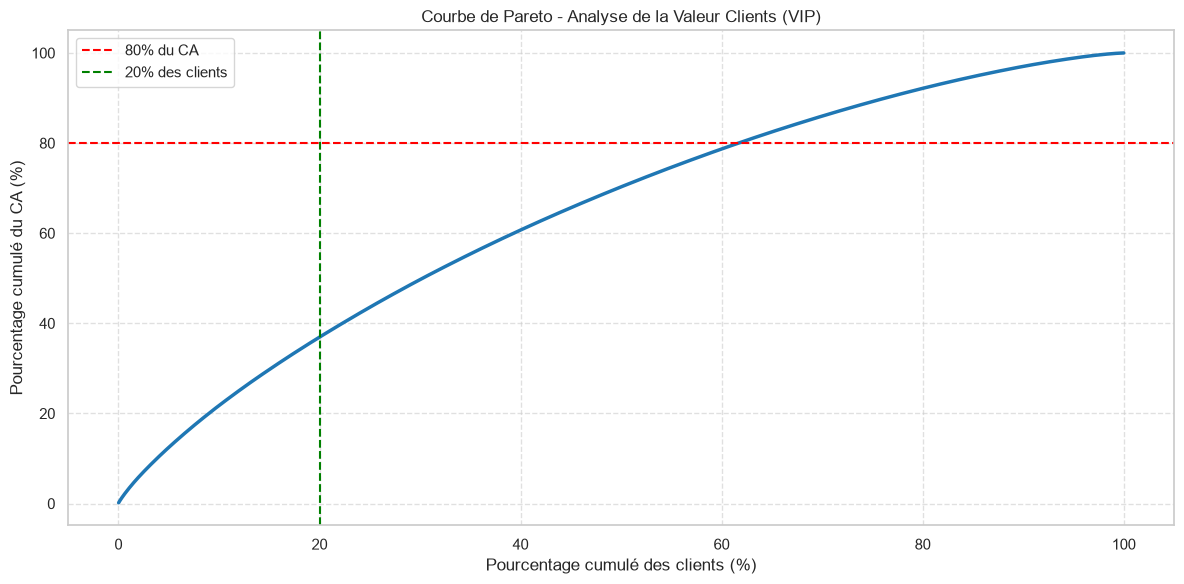

Le Top 10% des clients génère 21.7% du chiffre d'affaires total.


,id_client,chiffre_affaire_net,ca_cumul,part_ca_cumul_pct,part_clients_cumul_pct
0,CL_INCONNU,3196788.51,3196788.51,0.17,0.02
1,CLI00588,1611609.52,4808398.02,0.26,0.04
2,CLI01398,1524921.99,6333320.02,0.34,0.06
3,CLI02800,1368480.01,7701800.03,0.41,0.08
4,CLI01271,1363462.00,9065262.03,0.48,0.10
5,CLI02280,1359675.01,10424937.03,0.56,0.12
6,CLI01715,1326357.98,11751295.01,0.63,0.14
7,CLI00846,1321323.50,13072618.51,0.70,0.16
8,CLI04178,1311076.01,14383694.52,0.77,0.18
9,CLI00367,1306935.00,15690629.52,0.84,0.20


In [288]:


ventes_valides = ventes[ventes['statut_vente'].str.lower() == 'validée'].copy()

# CA par client trié par ordre décroissant
ca_clients = ventes_valides.groupby('id_client')['chiffre_affaire_net'].sum().reset_index()
ca_clients = ca_clients.sort_values(by='chiffre_affaire_net', ascending=False).reset_index(drop=True)

# Calcul du cumul et des pourcentages cumulés
ca_clients['ca_cumul'] = ca_clients['chiffre_affaire_net'].cumsum()
ca_clients['part_ca_cumul_pct'] = (ca_clients['ca_cumul'] / ca_clients['chiffre_affaire_net'].sum()) * 100
ca_clients['part_clients_cumul_pct'] = ((ca_clients.index + 1) / len(ca_clients)) * 100

# Visualisation Courbe de Pareto
plt.figure(figsize=(12, 6))
plt.plot(ca_clients['part_clients_cumul_pct'], ca_clients['part_ca_cumul_pct'], color='#1f77b4', linewidth=2.5)
plt.axhline(80, color='red', linestyle='--', label='80% du CA')
plt.axvline(20, color='green', linestyle='--', label='20% des clients')
plt.title("Courbe de Pareto - Analyse de la Valeur Clients (VIP)")
plt.xlabel("Pourcentage cumulé des clients (%)")
plt.ylabel("Pourcentage cumulé du CA (%)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# Part du CA générée par le top 10% des clients
top_10_pct = int(len(ca_clients) * 0.10)
ca_top_10 = ca_clients.head(top_10_pct)['chiffre_affaire_net'].sum()
ca_total = ca_clients['chiffre_affaire_net'].sum()
print(f"Le Top 10% des clients génère {(ca_top_10 / ca_total) * 100:.1f}% du chiffre d'affaires total.")
display(ca_clients.head(10))

Interprétation : Le chiffre d'affaires est bien réparti et ne suit pas la règle stricte du 80/20 : les 20% des clients génèrent environ 37% du chiffre d'affaires total, montrant une base de clientèle moins dépendante d'un petit groupe d'acheteurs.

Conclusion métier : L'entreprise possède un portefeuille client équilibré. Elle doit maintenir une stratégie marketing globale pour l'ensemble de sa clientèle tout en offrant des avantages ciblés aux acheteurs les plus réguliers.

### 3. Analyse des produits.

A. Produits les plus rentables.

C:\Users\Agatte_Nganzeu\AppData\Local\Temp\ipykernel_22944\3362323053.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_produits, x='ca_total', y='nom_produit', palette='viridis')


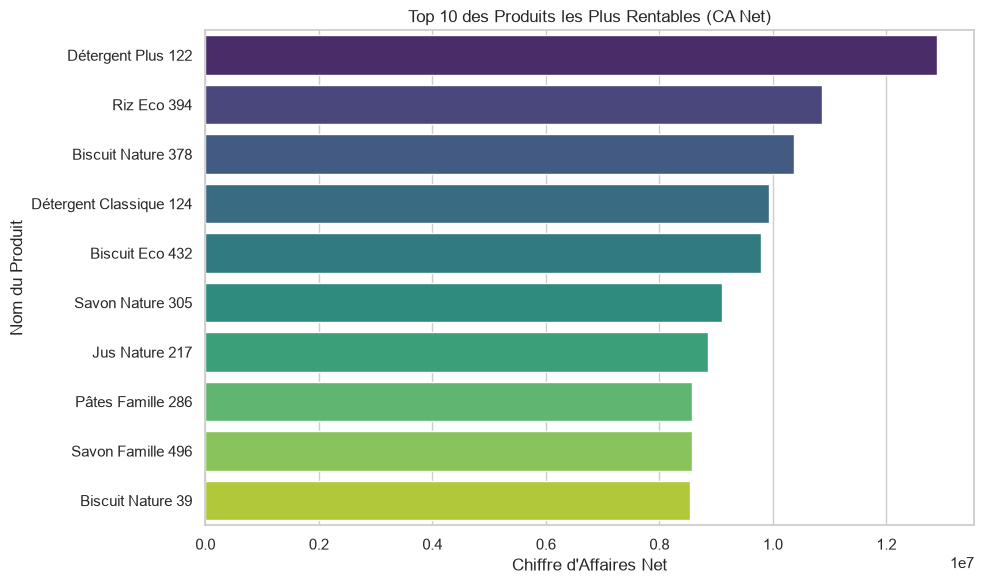

,nom_produit,ca_total
121,Détergent Plus 122,12898446.02
399,Riz Eco 394,10862196.02
19,Biscuit Nature 378,10365659.50
90,Détergent Classique 124,9923291.97
9,Biscuit Eco 432,9783841.98
441,Savon Nature 305,9104972.99
290,Jus Nature 217,8863774.00
363,Pâtes Famille 286,8575055.99
434,Savon Famille 496,8574114.00
20,Biscuit Nature 39,8541120.03


In [289]:

pd.set_option('display.float_format', lambda x: '%.2f' % x)

# Fusionner pour récupérer le nom des produits
df = pd.merge(ventes, produits, on='id_produit', how='left')
ventes_valides = df[df['statut_vente'].str.lower() == 'validée'].copy()

# Calcul du CA total par nom de produit
top_produits = ventes_valides.groupby('nom_produit').agg(
    ca_total=('chiffre_affaire_net', 'sum')
).reset_index().sort_values(by='ca_total', ascending=False).head(10)

# Affichage du graphique
plt.figure(figsize=(10, 6))
sns.barplot(data=top_produits, x='ca_total', y='nom_produit', palette='viridis')
plt.title('Top 10 des Produits les Plus Rentables (CA Net)')
plt.xlabel('Chiffre d\'Affaires Net')
plt.ylabel('Nom du Produit')
plt.tight_layout()
plt.show()

display(top_produits)

Interprétation : Le "Détergent Plus 122" et le "Riz Eco 394" dominent les ventes et rapportent le plus d'argent à l'entreprise.

Conclusion métier : Il faut s'assurer de ne jamais manquer de ces produits phares en stock pour continuer à maximiser le chiffre d'affaires.

B. Produits les moins performants.

C:\Users\Agatte_Nganzeu\AppData\Local\Temp\ipykernel_22944\4202279128.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=produits_faibles, x='ca_total', y='nom_produit', palette='rocket')


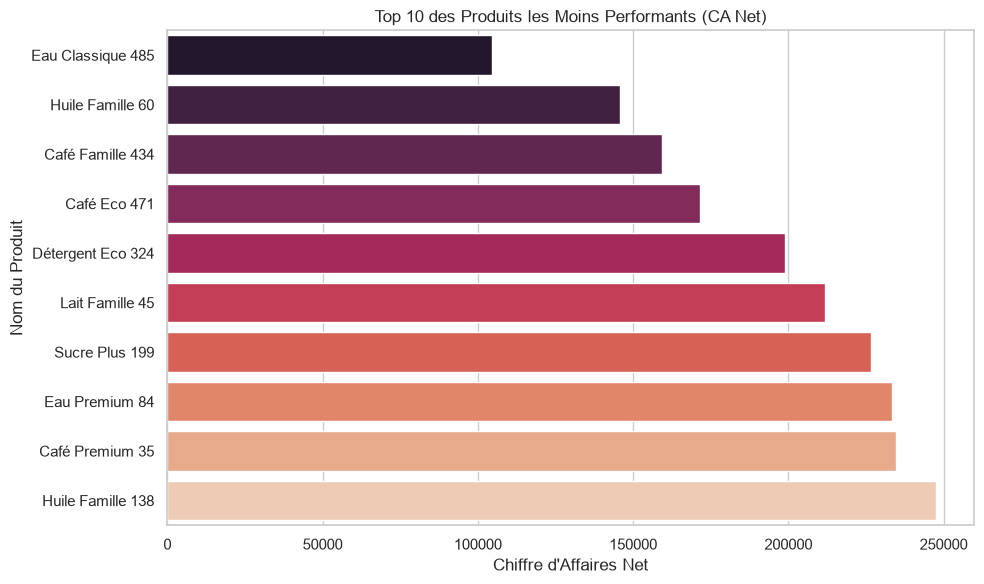

,nom_produit,ca_total
141,Eau Classique 485,104640.00
247,Huile Famille 60,145830.00
65,Café Famille 434,159192.00
56,Café Eco 471,171500.00
106,Détergent Eco 324,198915.00
330,Lait Famille 45,211801.50
490,Sucre Plus 199,226734.00
175,Eau Premium 84,233244.00
87,Café Premium 35,234544.00
237,Huile Famille 138,247408.50


In [290]:


# Désactiver la notation scientifique
pd.set_option('display.float_format', lambda x: '%.2f' % x)

# Fusionner pour récupérer le nom des produits
df = pd.merge(ventes, produits, on='id_produit', how='left')
ventes_valides = df[df['statut_vente'].str.lower() == 'validée'].copy()

# Calcul du CA total par nom de produit (les moins performants)
produits_faibles = ventes_valides.groupby('nom_produit').agg(
    ca_total=('chiffre_affaire_net', 'sum')
).reset_index().sort_values(by='ca_total', ascending=True).head(10)

# Affichage du graphique
plt.figure(figsize=(10, 6))
sns.barplot(data=produits_faibles, x='ca_total', y='nom_produit', palette='rocket')
plt.title('Top 10 des Produits les Moins Performants (CA Net)')
plt.xlabel('Chiffre d\'Affaires Net')
plt.ylabel('Nom du Produit')
plt.tight_layout()
plt.show()

display(produits_faibles)

Interprétation : L'"Eau Classique 485" et l'"Huile Famille 60" génèrent les chiffres d'affaires les plus faibles de la gamme.

Conclusion métier : Il conviendrait de revoir leur visibilité, leur prix ou d'envisager leur remplacement par des articles plus demandés.

C. Produits a forte demande.

C:\Users\Agatte_Nganzeu\AppData\Local\Temp\ipykernel_22944\161521834.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=produits_forte_demande, x='quantite_totale', y='nom_produit', palette='crest')


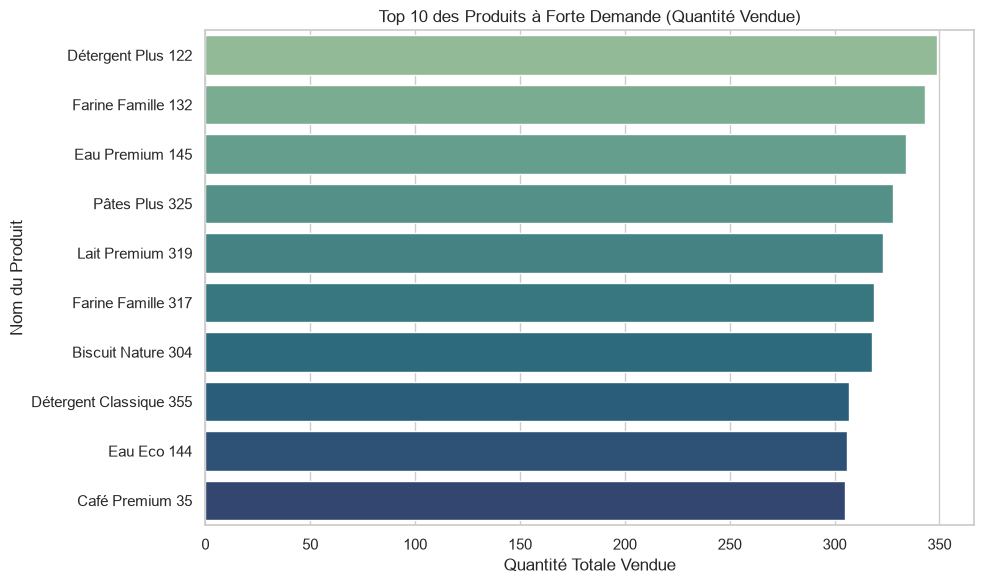

,nom_produit,quantite_totale
121,Détergent Plus 122,349
193,Farine Famille 132,343
169,Eau Premium 145,334
383,Pâtes Plus 325,328
339,Lait Premium 319,323
197,Farine Famille 317,319
17,Biscuit Nature 304,318
97,Détergent Classique 355,307
143,Eau Eco 144,306
87,Café Premium 35,305


In [291]:


pd.set_option('display.float_format', lambda x: '%.2f' % x)


df = pd.merge(ventes, produits, on='id_produit', how='left')
ventes_valides = df[df['statut_vente'].str.lower() == 'validée'].copy()

# Calcul par quantité totale
produits_forte_demande = ventes_valides.groupby('nom_produit').agg(
    quantite_totale=('quantite', 'sum')
).reset_index().sort_values(by='quantite_totale', ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(data=produits_forte_demande, x='quantite_totale', y='nom_produit', palette='crest')
plt.title('Top 10 des Produits à Forte Demande (Quantité Vendue)')
plt.xlabel('Quantité Totale Vendue')
plt.ylabel('Nom du Produit')
plt.tight_layout()
plt.show()

display(produits_forte_demande)

Interprétation : Le "Détergent Plus 122" et la "Farine Famille 132" sont les articles achetés en plus grand nombre d'exemplaires par les clients.   

Conclusion métier : Ce sont des produits de grande consommation qu'il faut maintenir en stock permanent pour éviter toute rupture auprès des acheteurs.   

D. Produits a faible rotation.

C:\Users\Agatte_Nganzeu\AppData\Local\Temp\ipykernel_22944\2550939178.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=produits_faible_rotation, x='quantite_totale', y='nom_produit', palette='mako')


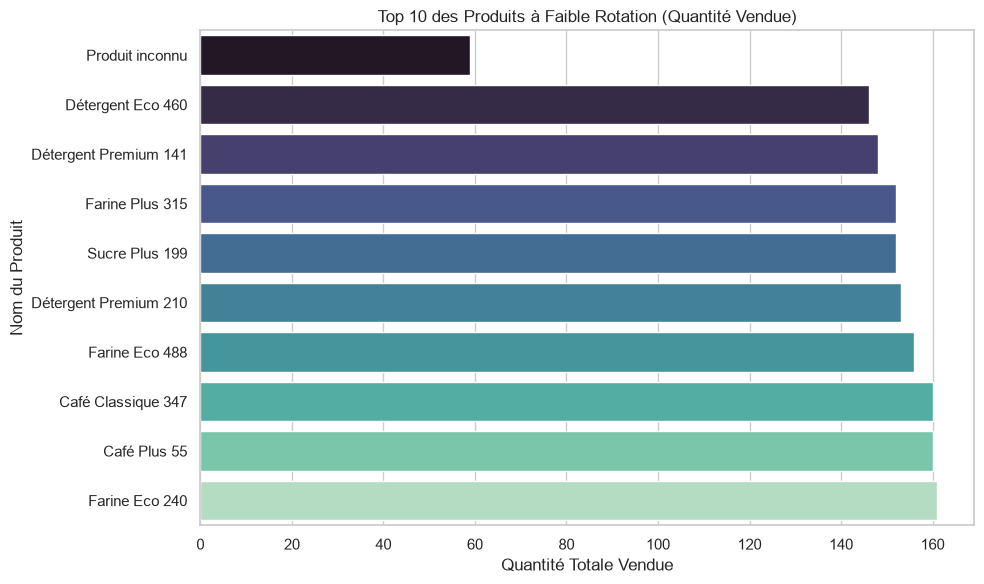

,nom_produit,quantite_totale
341,Produit inconnu,59
110,Détergent Eco 460,146
131,Détergent Premium 141,148
211,Farine Plus 315,152
490,Sucre Plus 199,152
133,Détergent Premium 210,153
191,Farine Eco 488,156
45,Café Classique 347,160
83,Café Plus 55,160
184,Farine Eco 240,161


In [292]:


pd.set_option('display.float_format', lambda x: '%.2f' % x)

df = pd.merge(ventes, produits, on='id_produit', how='left')
ventes_valides = df[df['statut_vente'].str.lower() == 'validée'].copy()

# Calcul par quantité totale (ascendant pour les plus faibles)
produits_faible_rotation = ventes_valides.groupby('nom_produit').agg(
    quantite_totale=('quantite', 'sum')
).reset_index().sort_values(by='quantite_totale', ascending=True).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(data=produits_faible_rotation, x='quantite_totale', y='nom_produit', palette='mako')
plt.title('Top 10 des Produits à Faible Rotation (Quantité Vendue)')
plt.xlabel('Quantité Totale Vendue')
plt.ylabel('Nom du Produit')
plt.tight_layout()
plt.show()

display(produits_faible_rotation)

Interprétation : Le "Produit inconnu" et le "Détergent Eco 460" se vendent en très petites quantités et bougent très peu en stock.   

Conclusion métier : Il faut identifier le produit inconnu et réduire ou stopper les commandes des articles qui ne se vendent pas pour éviter de bloquer l'argent inutilement.

E. Analyse des marge par categorie.

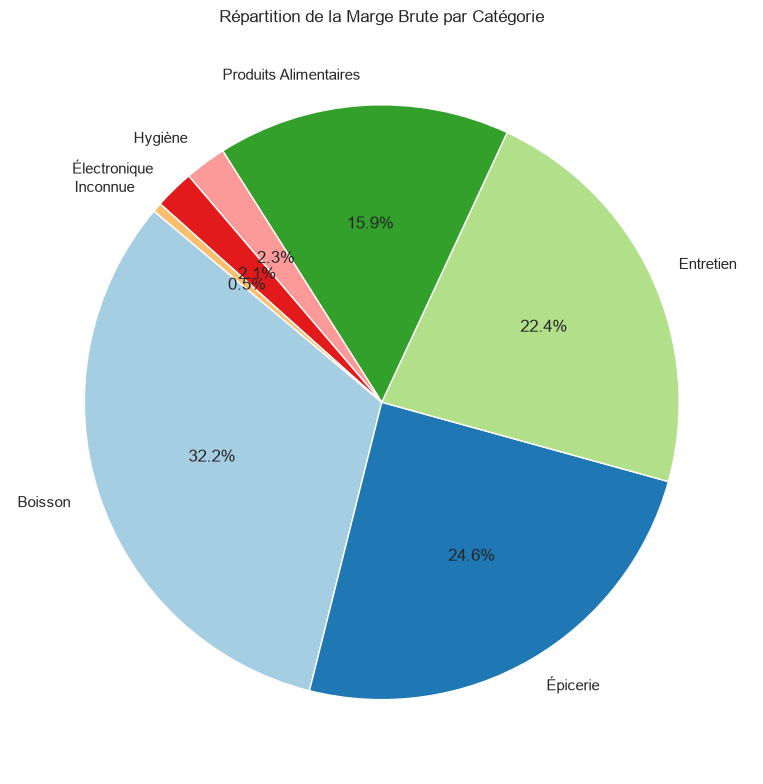

,categorie,cout_achat_unitaire_moyen,volume_total,ca_total,marge_brute_totale
0,Boisson,12175.02,38682,618629403.35,148611743.35
6,Épicerie,11797.57,32103,488408160.39,113581158.39
1,Entretien,12809.17,22486,390334047.28,103241323.28
4,Produits Alimentaires,12451.64,17051,286521529.34,73392416.34
2,Hygiène,13296.50,2135,38580863.52,10456777.52
5,Électronique,12183.83,1926,33954950.53,9854291.53
3,Inconnue,17683.38,707,14549850.49,2352111.99


In [293]:

pd.set_option('display.float_format', lambda x: '%.2f' % x)

df = pd.merge(ventes, produits, on='id_produit', how='left')
ventes_valides = df[df['statut_vente'].str.lower() == 'validée'].copy()

# Calcul du coût total d'achat (quantité * coût_achat_unitaire) et de la marge brute
ventes_valides['cout_total_achat'] = ventes_valides['quantite'] * ventes_valides['cout_achat_unitaire']
ventes_valides['marge_brute'] = ventes_valides['chiffre_affaire_net'] - ventes_valides['cout_total_achat']

# Agrégation par catégorie
analyse_marge = ventes_valides.groupby('categorie').agg(
    cout_achat_unitaire_moyen=('cout_achat_unitaire', 'mean'),
    volume_total=('quantite', 'sum'),
    ca_total=('chiffre_affaire_net', 'sum'),
    marge_brute_totale=('marge_brute', 'sum')
).reset_index().sort_values(by='marge_brute_totale', ascending=False)

# Affichage d'un graphique en camembert pour la marge brute
plt.figure(figsize=(8, 8))
plt.pie(analyse_marge['marge_brute_totale'], labels=analyse_marge['categorie'], autopct='%1.1f%%', startangle=140, colors=plt.cm.Paired.colors)
plt.title('Répartition de la Marge Brute par Catégorie')
plt.tight_layout()
plt.show()

display(analyse_marge)

Interprétation : Les catégories "Boisson", "Épicerie" et "Hygiène" génèrent les marges brutes les plus élevées, tandis que la catégorie "Inconnue" pèse très peu (2,4%).   

Conclusion métier : La rentabilité est bien répartie entre les grandes familles de produits.

F. Analyse ABC des produits.

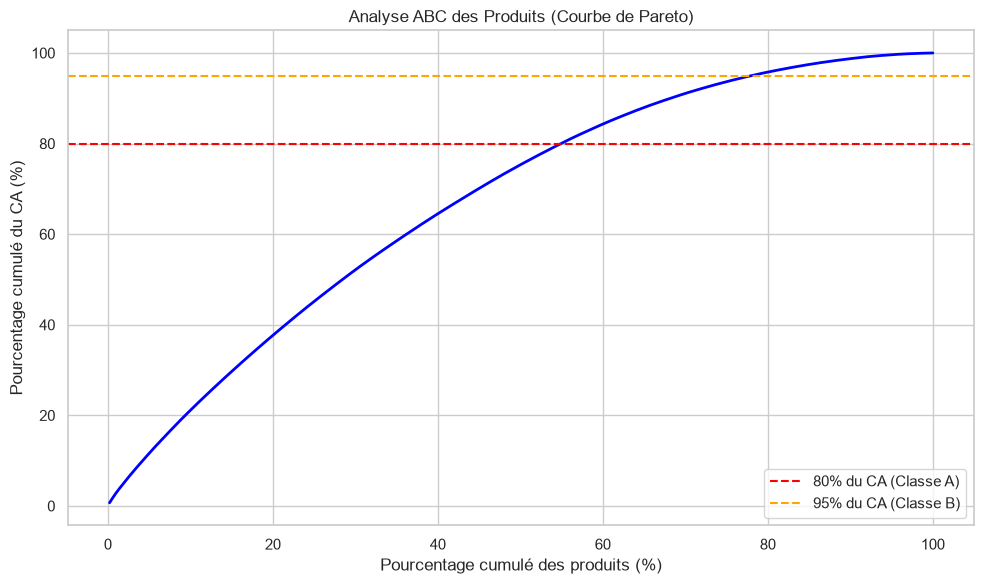

,nom_produit,ca_total,ca_cumul,part_ca_cumul_pct,part_produits_cumul_pct,classe_abc
121,Détergent Plus 122,12898446.02,12898446.02,0.69,0.20,A
399,Riz Eco 394,10862196.02,23760642.04,1.27,0.40,A
19,Biscuit Nature 378,10365659.50,34126301.54,1.82,0.60,A
90,Détergent Classique 124,9923291.97,44049593.51,2.35,0.80,A
9,Biscuit Eco 432,9783841.98,53833435.49,2.88,1.00,A
441,Savon Nature 305,9104972.99,62938408.49,3.36,1.20,A
290,Jus Nature 217,8863774.00,71802182.48,3.84,1.40,A
363,Pâtes Famille 286,8575055.99,80377238.47,4.30,1.60,A
434,Savon Famille 496,8574114.00,88951352.47,4.75,1.80,A
20,Biscuit Nature 39,8541120.03,97492472.50,5.21,2.00,A


In [294]:

pd.set_option('display.float_format', lambda x: '%.2f' % x)

df = pd.merge(ventes, produits, on='id_produit', how='left')
ventes_valides = df[df['statut_vente'].str.lower() == 'validée'].copy()

# Calcul du CA par produit
abc = ventes_valides.groupby('nom_produit').agg(
    ca_total=('chiffre_affaire_net', 'sum')
).reset_index().sort_values(by='ca_total', ascending=False)

# Calcul des pourcentages cumulés
abc['ca_cumul'] = abc['ca_total'].cumsum()
abc['part_ca_cumul_pct'] = abc['ca_cumul'] / abc['ca_total'].sum() * 100
abc['part_produits_cumul_pct'] = (abc.reset_index().index + 1) / len(abc) * 100

# Attribution des classes ABC
def assigner_classe(val):
    if val <= 80:
        return 'A'
    elif val <= 95:
        return 'B'
    else:
        return 'C'

abc['classe_abc'] = abc['part_ca_cumul_pct'].apply(assigner_classe)

# Affichage graphique (Courbe de Pareto)
plt.figure(figsize=(10, 6))
plt.plot(abc['part_produits_cumul_pct'], abc['part_ca_cumul_pct'], color='b', linewidth=2)
plt.axhline(80, color='r', linestyle='--', label='80% du CA (Classe A)')
plt.axhline(95, color='orange', linestyle='--', label='95% du CA (Classe B)')
plt.title('Analyse ABC des Produits (Courbe de Pareto)')
plt.xlabel('Pourcentage cumulé des produits (%)')
plt.ylabel('Pourcentage cumulé du CA (%)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

display(abc.head(10))

Interprétation : environ 58 % des produits réalisent les premiers 80 % du chiffre d'affaires.

Conclusion métier : La gamme est bien diversifiée et équilibrée. Il faut veiller à suivre un large choix d'articles plutôt que de se focaliser sur une seule référence.

### 4. Analyse geographique.

A. Comparaison des villes.

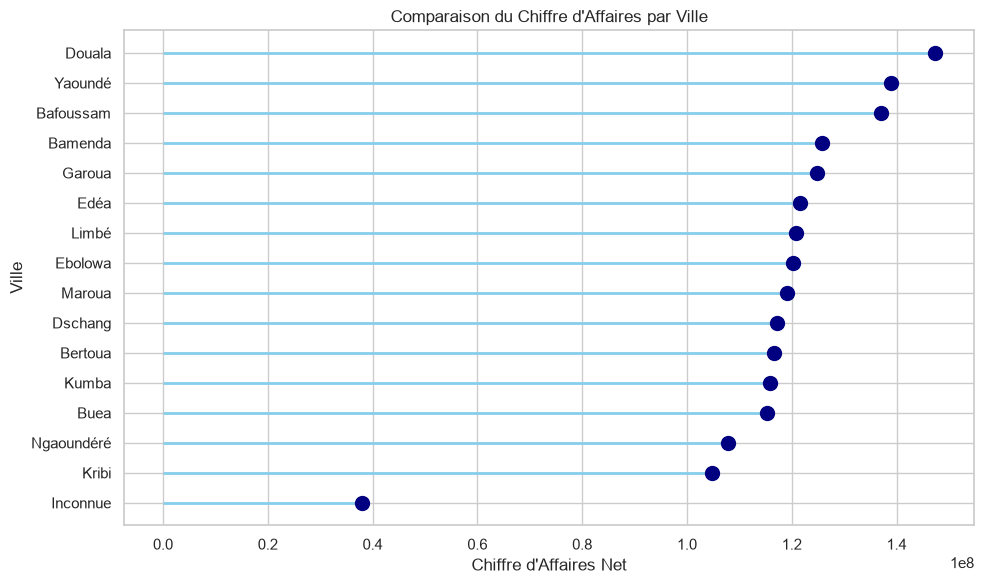

,ville,ca_total,volume_total
4,Douala,147415564.93,8991
15,Yaoundé,138926321.08,8455
0,Bafoussam,136951977.62,8642
1,Bamenda,125809391.66,7564
8,Garoua,124809851.31,7699
7,Edéa,121489406.64,7457
12,Limbé,120789596.14,7368
6,Ebolowa,120313944.58,7337
13,Maroua,119061014.73,7334
5,Dschang,117131207.12,7352


In [295]:


pd.set_option('display.float_format', lambda x: '%.2f' % x)

# Fusionner pour récupérer la ville des clients
df = pd.merge(ventes, clients, on='id_client', how='left')
ventes_valides = df[df['statut_vente'].str.lower() == 'validée'].copy()

# Agrégation par ville
comparaison_villes = ventes_valides.groupby('ville').agg(
    ca_total=('chiffre_affaire_net', 'sum'),
    volume_total=('quantite', 'sum')
).reset_index().sort_values(by='ca_total', ascending=True)

# Affichage d'un graphique en sucettes (Lollipop chart)
plt.figure(figsize=(10, 6))
plt.hlines(y=comparaison_villes['ville'], xmin=0, xmax=comparaison_villes['ca_total'], color='skyblue', linewidth=2)
plt.plot(comparaison_villes['ca_total'], comparaison_villes['ville'], "o", markersize=10, color='navy')
plt.title('Comparaison du Chiffre d\'Affaires par Ville')
plt.xlabel('Chiffre d\'Affaires Net')
plt.ylabel('Ville')
plt.tight_layout()
plt.show()

display(comparaison_villes.sort_values(by='ca_total', ascending=False))

Interprétation : Douala et Yaoundé réalisent le plus gros chiffre d'affaires, suivies de près par Bafoussam, tandis que la catégorie "Inconnue" ferme la marche avec des ventes très faibles.

Conclusion métier : Les grandes métropoles portent l'essentiel de l'activité. En complément de la protection de nos marchés forts, il faut concentrer les efforts marketing sur les zones a faible potentiel pour élargir la clientèle et augmenter le chiffre d'affaires global à long terme.



B. Comparaison des magasins.

C:\Users\Agatte_Nganzeu\AppData\Local\Temp\ipykernel_22944\2883385355.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=comparaison_magasins, x='nom_magasin', y='ca_total', palette='magma')


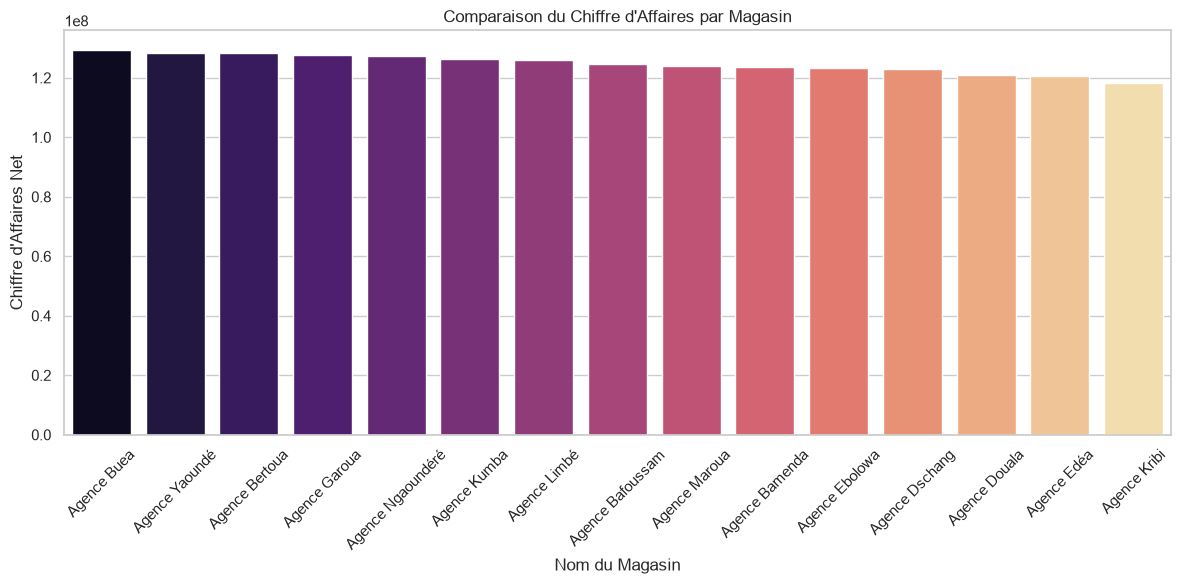

,nom_magasin,ca_total,volume_total
3,Agence Buea,129421243.49,7728
14,Agence Yaoundé,128358751.13,8053
2,Agence Bertoua,128308875.11,7760
8,Agence Garoua,127604561.12,7799
13,Agence Ngaoundéré,127300417.96,7779
10,Agence Kumba,126198591.08,7728
11,Agence Limbé,125864679.45,7945
0,Agence Bafoussam,124527288.07,7591
12,Agence Maroua,123789633.13,7726
1,Agence Bamenda,123717378.04,7650


In [296]:

pd.set_option('display.float_format', lambda x: '%.2f' % x)

# Fusionner pour récupérer le nom des magasins
df = pd.merge(ventes, magasins, on='id_magasin', how='left')
ventes_valides = df[df['statut_vente'].str.lower() == 'validée'].copy()

# Agrégation par nom de magasin
comparaison_magasins = ventes_valides.groupby('nom_magasin').agg(
    ca_total=('chiffre_affaire_net', 'sum'),
    volume_total=('quantite', 'sum')
).reset_index().sort_values(by='ca_total', ascending=False)

# Affichage graphique en barres verticales
plt.figure(figsize=(12, 6))
sns.barplot(data=comparaison_magasins, x='nom_magasin', y='ca_total', palette='magma')
plt.title('Comparaison du Chiffre d\'Affaires par Magasin')
plt.xlabel('Nom du Magasin')
plt.ylabel('Chiffre d\'Affaires Net')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display(comparaison_magasins)

Interprétation : L'Agence Buea et l'Agence Yaoundé réalisent les chiffres d'affaires les plus élevés, tandis que l'Agence Kribi enregistre les performances les plus faibles, avec des écarts globaux assez resserrés entre les agences.   

Conclusion métier : Les ventes sont bien réparties sur le réseau, mais il conviendra de soutenir les agences a faible potentiel pour stimuler leur activité et les alignes sur les meilleures agences.   

C. Identification des zones a fort potentiel.

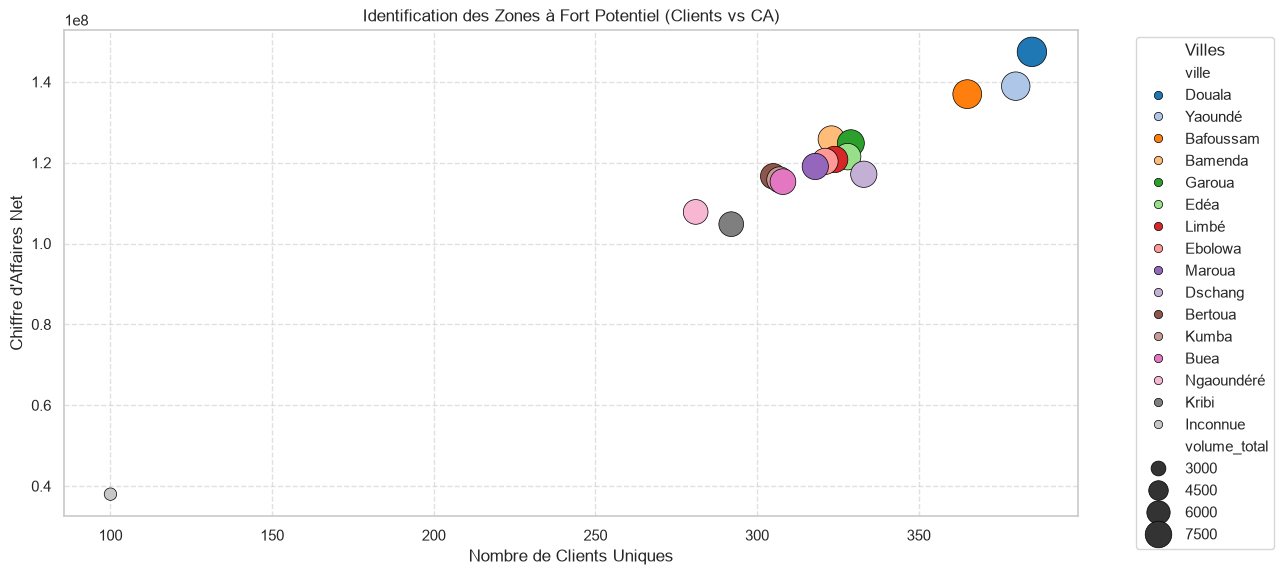

,ville,ca_total,volume_total,nombre_clients,panier_moyen
4,Douala,147415564.93,8991,385,42034.66
15,Yaoundé,138926321.08,8455,380,41090.30
0,Bafoussam,136951977.62,8642,365,41077.38
1,Bamenda,125809391.66,7564,323,42879.82
8,Garoua,124809851.31,7699,329,40614.99
7,Edéa,121489406.64,7457,328,40348.52
12,Limbé,120789596.14,7368,324,41154.89
6,Ebolowa,120313944.58,7337,321,41359.21
13,Maroua,119061014.73,7334,318,41354.99
5,Dschang,117131207.12,7352,333,38939.90


In [297]:

pd.set_option('display.float_format', lambda x: '%.2f' % x)

# Fusionner pour récupérer la ville des clients
df = pd.merge(ventes, clients, on='id_client', how='left')
ventes_valides = df[df['statut_vente'].str.lower() == 'validée'].copy()

# Agrégation par ville
potentiel_villes = ventes_valides.groupby('ville').agg(
    ca_total=('chiffre_affaire_net', 'sum'),
    volume_total=('quantite', 'sum'),
    nombre_clients=('id_client', 'nunique'),
    panier_moyen=('chiffre_affaire_net', 'mean')
).reset_index().sort_values(by='ca_total', ascending=False)

# Affichage graphique avec une palette étendue (tab20) pour des couleurs uniques
plt.figure(figsize=(13, 6))
sns.scatterplot(
    data=potentiel_villes, 
    x='nombre_clients', 
    y='ca_total', 
    size='volume_total', 
    sizes=(80, 450), 
    hue='ville', 
    palette='tab20',
    edgecolor='black',
    linewidth=0.5
)

# Positionner la légende à l'extérieur
plt.title('Identification des Zones à Fort Potentiel (Clients vs CA)')
plt.xlabel('Nombre de Clients Uniques')
plt.ylabel('Chiffre d\'Affaires Net')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title='Villes', frameon=True)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

display(potentiel_villes)

Interprétation : Le graphique met en évidence les marchés matures comme Douala et Yaoundé (forte concentration de clients et CA élevé) face aux zones à fort potentiel de développement comme Bafoussam ou Bamenda.   

Conclusion métier : Il faut consolider les positions dans les grandes métropoles tout en ciblant les villes intermédiaires pour stimuler l'acquisition de nouveaux clients.   

D. Analyse des differences de comportement selon les points de vente.

C:\Users\Agatte_Nganzeu\AppData\Local\Temp\ipykernel_22944\392169183.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=comportement_magasins, x='panier_moyen', y='nom_magasin', palette='coolwarm')


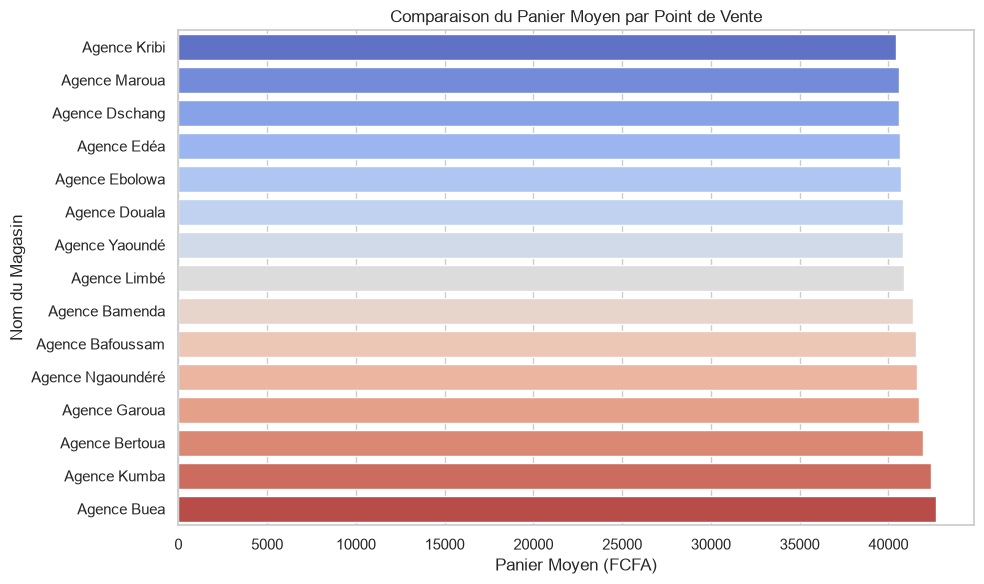

,nom_magasin,panier_moyen,quantite_moyenne_vente,nombre_transactions
3,Agence Buea,42685.11,2.55,3032
10,Agence Kumba,42405.44,2.60,2976
2,Agence Bertoua,41931.00,2.54,3060
8,Agence Garoua,41728.11,2.55,3058
13,Agence Ngaoundéré,41615.04,2.54,3059
0,Agence Bafoussam,41536.79,2.53,2998
1,Agence Bamenda,41363.22,2.56,2991
11,Agence Limbé,40878.43,2.58,3079
14,Agence Yaoundé,40839.56,2.56,3143
4,Agence Douala,40812.65,2.50,2965


In [298]:

pd.set_option('display.float_format', lambda x: '%.2f' % x)

# Fusionner pour récupérer le nom des magasins
df = pd.merge(ventes, magasins, on='id_magasin', how='left')
ventes_valides = df[df['statut_vente'].str.lower() == 'validée'].copy()

# Analyse comportementale par magasin (panier moyen et quantité moyenne par transaction)
comportement_magasins = ventes_valides.groupby('nom_magasin').agg(
    panier_moyen=('chiffre_affaire_net', 'mean'),
    quantite_moyenne_vente=('quantite', 'mean'),
    nombre_transactions=('id_vente', 'count')
).reset_index().sort_values(by='panier_moyen', ascending=True)

# Affichage graphique en barres horizontales
plt.figure(figsize=(10, 6))
sns.barplot(data=comportement_magasins, x='panier_moyen', y='nom_magasin', palette='coolwarm')
plt.title('Comparaison du Panier Moyen par Point de Vente')
plt.xlabel('Panier Moyen (FCFA)')
plt.ylabel('Nom du Magasin')
plt.tight_layout()
plt.show()

display(comportement_magasins.sort_values(by='panier_moyen', ascending=False))

Interprétation : Le panier moyen est remarquablement homogène d'une agence à l'autre (oscillant globalement autour de 40 500 à 42 700 FCFA), l'Agence Buea affichant la valeur légèrement la plus élevée.   

Conclusion métier : Le comportement d'achat des clients est uniforme sur l'ensemble du réseau, quelle que soit la région. Les efforts marketing doivent donc se concentrer sur l'augmentation du volume de transactions plutôt que sur la taille du panier.

### 5. Analyse des commerciaux.

A. Analyse des commerciaux.

In [299]:
import os
import pandas as pd

pd.set_option('display.float_format', lambda x: '%.2f' % x)

# Fusionner les tables pour récupérer le nom du commercial et le coût d'achat des produits
df = pd.merge(ventes, commerciaux, on='id_commercial', how='left')
df = pd.merge(df, produits, on='id_produit', how='left')

ventes_valides = df[df['statut_vente'].str.lower() == 'validée'].copy()

# Calcul du coût total d'achat et de la marge brute par ligne
ventes_valides['cout_total_achat'] = ventes_valides['quantite'] * ventes_valides['cout_achat_unitaire']
ventes_valides['marge_brute'] = ventes_valides['chiffre_affaire_net'] - ventes_valides['cout_total_achat']

# Agrégation par commercial
performance_commerciaux = ventes_valides.groupby('nom_commercial').agg(
    ca_total=('chiffre_affaire_net', 'sum'),
    nombre_ventes=('id_vente', 'count'),
    volume_total=('quantite', 'sum'),
    marge_totale=('marge_brute', 'sum')
).reset_index().sort_values(by='ca_total', ascending=False)

display(performance_commerciaux)

,nom_commercial,ca_total,nombre_ventes,volume_total,marge_totale
14,Commercial 15,41193960.00,931,2481,10259794.00
30,Commercial 31,41133096.50,902,2458,10806887.50
39,Commercial 40,41084220.55,956,2530,9963765.55
0,Commercial 01,40649381.49,973,2445,9836404.49
7,Commercial 08,40577926.50,930,2475,10241205.50
32,Commercial 33,40015641.53,951,2432,10114752.53
41,Commercial 42,39864300.53,948,2421,10143189.53
6,Commercial 07,39563295.03,912,2408,9681966.53
44,Commercial 45,39370130.63,915,2366,9717337.63
20,Commercial 21,39266453.07,899,2349,9544234.07


Interprétation :
Chiffre d'affaires et Marge : Le Commercial 15 est le plus rentable avec le CA le plus élevé (541,19 millions) et la plus grande marge (110,26 millions).

Nombre de ventes : Le Commercial 23 réalise le plus grand nombre de transactions (974 ventes).

Volume de ventes : Le Commercial 40 vend la plus grande quantité d'articles (2 530 unités).


Conclusion métier : Le Commercial 15 tire l'entreprise vers le haut en matière de valeur et de profit. Il est conseillé d'analyser ses méthodes de vente pour les partager avec le reste de l'équipe et récompenser ces performances.

B. Taux d'atteinte des objectifs.

In [300]:

pd.set_option('display.float_format', lambda x: '%.2f' % x)


# Fusionner pour récupérer les objectifs et les noms des commerciaux
df = pd.merge(ventes, commerciaux, on='id_commercial', how='left')
ventes_valides = df[df['statut_vente'].str.lower() == 'validée'].copy()

# Calcul du CA réalisé par commercial et comparaison avec l'objectif
taux_objectifs = ventes_valides.groupby(['nom_commercial', 'objectif_mensuel_fcfa']).agg(
    ca_total=('chiffre_affaire_net', 'sum')
).reset_index()

taux_objectifs['taux_atteinte_pct'] = (taux_objectifs['ca_total'] / taux_objectifs['objectif_mensuel_fcfa']) * 100
taux_objectifs = taux_objectifs.sort_values(by='taux_atteinte_pct', ascending=False)

display(taux_objectifs)

,nom_commercial,objectif_mensuel_fcfa,ca_total,taux_atteinte_pct
11,Commercial 12,1500000.00,37848248.62,2523.22
16,Commercial 17,1750000.00,36591055.02,2090.92
14,Commercial 15,2000000.00,41193960.00,2059.70
30,Commercial 31,2000000.00,41133096.50,2056.65
25,Commercial 26,1750000.00,35035242.05,2002.01
32,Commercial 33,2000000.00,40015641.53,2000.78
20,Commercial 21,2500000.00,39266453.07,1570.66
6,Commercial 07,3000000.00,39563295.03,1318.78
24,Commercial 25,3000000.00,36966261.03,1232.21
39,Commercial 40,3500000.00,41084220.55,1173.83


Interprétation :
Surperformance massive : Tous les commerciaux affichent des taux d'atteinte largement supérieurs à 100 % (allant d'environ 483 % à plus de 2 500 %).

Le plus performant : Le Commercial 12 arrive en tête avec un taux impressionnant de 2 523,22 % de son objectif, suivi de près par les Commerciaux 17, 15 et 31 (qui dépassent les 2 000 %).


Conclusion métier :
Les objectifs mensuels fixés sont totalement déconnectés de la réalité du terrain et très largement sous-évalués par rapport au potentiel réel de vente.

Il est urgent de réajuster et de revoir à la hausse la grille des objectifs pour les prochains mois afin qu'elle constitue un réel défi motivant pour l'équipe commerciale et non une simple formalité dépassée dès les premiers jours.